# Patent technology networks: a bipartite analysis of country–technology relationships

---

## Introduction 

This notebook looks at the **technological specialisation** of countries that filed patents with the European Patent Office (EPO) in 2023.

I treat the data as a **bipartite network** which means it has 2 types of nodes that only connect accros the 2 groups:
- **Countries** — the home country of each patent applicant
- **IPC technology codes** — International Patent Classification main group codes (part before `/`) --> for example `G01R33/561` becomes `G01R33`

A link between a country and an IPC code means that the country has **revealed technology advantage** (RTA > 1) in that technology area. In other words, this means the country files relatively more patents in that area than the global average, compared with its overall patenting activity. 

The setup will be very similar to the country-product trade network studied in class. In that clase, countries were linked to products they export with RCA > 1. Here, instead of export products, I use IPC technology codes, and instead of export value, I use patent counts.

The question I want to find an answer to is:
> Which countries share significantly similar patterns of technological specialisation in 2023 EP patent data, and can I identify communities of countries with aligned technology focus areas?


## Step 1: Import libraries and load the data

In [35]:
import zipfile
import io
import ast
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from scipy.stats import pearsonr
from collections import defaultdict, Counter
from bicm import BipartiteGraph      

# setting the plot aesthetics
plt.style.use('default')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

#### Data Sources

Patent data is like a proxy for technological activity. A country that files many patents in a specific technology area is signaling that it's actively working in that field. By connecting countries to IPC codes, I can study which countries specialise in which technology and whether different countries have similar specialization patterns.

The data comes from 2 zip archives:
- **`2023_title_publ_inventor.zip`** - this one contains a large csv with metadata for about 97600 patents published by the European Patent Office (EPO) in 2023. Each row is one patent. The columns include the publication number (a unique ID), the applicant (the company / individual that owns the patent) and other information like the publication date and title
- **`2023_ipc_codes.zip`** - this one contains around 91000 small text files, one per patent. Each file is named like this `{patent_id}_ipc.txt` and list the IPC (International Patent Classification) codes assigned to that patent. These codes describe what technology the patent covers.

From the metadata csv, I'll use only 2 columns that I think are relevant for this analysis:
- **`publication.number`** - unique id for each patent
- **`applicant`** - a json formatted list which has information about who owns the patent + a 2-letter country code (this will be the country variable I'll use across the analysis). The reason why I decided to use this is because I want to know which country's entities are filing patents. 





#### Loading the metadata

In [36]:
data_dir = os.path.join('..', 'data', 'raw')  # see data/README.md
inventor_zip_path = os.path.join(data_dir, '2023_title_publ_inventor.zip')
ipc_zip_path = os.path.join(data_dir, '2023_ipc_codes.zip')

with zipfile.ZipFile(inventor_zip_path) as z:
    with z.open('2023_title_publ_inventor.csv') as f:
        df_raw = pd.read_csv(io.BytesIO(f.read()))

print(f"Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")


Shape: 97,661 rows, 12 columns


In [37]:
# Initial inspection of column names, data types, first rows of the raw csv

col_info = df_raw.dtypes.reset_index()
col_info.columns = ["Column", "Data type"]
print(col_info.to_string(index=False))

print('\n ---- First 3 rows ----')
first_rows = df_raw[[
    'title.en',
    'publication.number',
    'publication.date',
    'applicant',
    'inventor']].head(3)

print(first_rows.to_string(index=False))

                 Column Data type
               title.en    object
               inventor    object
       publication.date     int64
     publication.number     int64
    publication.country    object
              applicant    object
    representative.name    object
 representative.address    object
    representative.city    object
 representative.country    object
     application.number   float64
application.filing_date     int64

 ---- First 3 rows ----
                                                                                           title.en  publication.number  publication.date           applicant                                                                                                                                                                                                                                                                                                                                                                                        

In [38]:
# Checking missing values for all columns + whether there are duplicate publication numbers 

print("Missing values:")
print(df_raw.isnull().sum().to_string())
print()
print(f"Duplicate rows (with same publication.number): {df_raw.duplicated('publication.number').sum()}")
print(f"Unique publication numbers: {df_raw['publication.number'].nunique():,}")
print(f"Unique publication countries: {df_raw['publication.country'].unique()}")


Missing values:
title.en                      0
inventor                      0
publication.date              0
publication.number            0
publication.country           0
applicant                     0
representative.name        1000
representative.address     1004
representative.city        1000
representative.country     1000
application.number            0
application.filing_date       0

Duplicate rows (with same publication.number): 6092
Unique publication numbers: 91,569
Unique publication countries: ['EP']


**Main insights:**
- The csv contains 97600 rows, one per patent, with 12 columns. The columns I'll use for further analysis do not contain missing values (`publication.number` and `applicant`) which is a good sign. The columns containing missing values are not relevant for the analysis, hence there will be no additional preprocessing on these. 

#### Preprocessing of the metadata

The `applicant` column stores country information as a nested list. I need to apply parsing to be able to extract the country code from within this structure.

For this I have created a **function `parse_first_country`** which uses python's `ast.literal_eval` to parse the string as a python obj, then pulls the country fiels from the first entry in the list. I'll always take the *first* applicant because most patents have one primary applicant. After parsing, I have also applied some filtering:
- dropping the rows where `applicant_country` is missing as some patents might not have usable applicant information
- keeping only the rows where the country code matches this pattern `^[A-Z]{2}$` --> this will ensure that I only keep valid 2-letter country codes like 'DE', 'US', 'JP'
- deduplication on `patent_id` to keep at most 1 record per patent


In [39]:
def parse_first_country(val):
    """
    Parse the applicant string, extract the country code from the first applicant, and return it
    After parsing, rows with missing country values are removed and only valid 2-letter country codes
    (for example DE, US, JP) are kept. Deduplication is applied on `patent_id`.
    """
    lst = ast.literal_eval(str(val))
    if isinstance(lst, list) and len(lst) > 0:
        first_item = lst[0]
        if isinstance(first_item, dict):
            return first_item.get("country", None)
    return None

df_raw['applicant_country'] = df_raw['applicant'].apply(parse_first_country)

df_meta = df_raw[['publication.number', 'applicant_country']].copy()
df_meta = df_meta.dropna(subset=['applicant_country'])
df_meta = df_meta[df_meta['applicant_country'].str.match(r'^[A-Z]{2}$')]
df_meta['patent_id'] = df_meta['publication.number'].astype(str)
df_meta = df_meta.drop_duplicates(subset='patent_id')

print(f"Patents with valid applicant country: {len(df_meta):,}")
print(f"Unique countries: {df_meta['applicant_country'].nunique()}")


Patents with valid applicant country: 91,569
Unique countries: 100


In [40]:
print("Top 25 applicant countries by patent count:")
print(df_meta['applicant_country'].value_counts().head(25).to_string())

Top 25 applicant countries by patent count:
applicant_country
JP    20255
CN    19018
US    15281
KR    10876
DE     3995
IT     2225
CH     2111
NL     2039
GB     1745
SE     1664
FR     1489
TW     1410
ES     1290
FI      883
DK      819
BE      810
CA      745
IL      512
AT      482
IE      426
IN      353
PL      345
SG      341
BB      280
PT      167


#### Loading the IPC technology codes

For each patent that also has a metadata record, I'll read the corresponding IPC text file and parse each line. I'll only keep the part before the `/` which will reduce all specific sub-group codes to the more general main group level. Then, I'll keep only the codes with at least 4 chars.


In [41]:
# I'll look at some IPC files before loading all of them to ensure the truncation is done correctly 

print("IPC file contents (first 4 files):")
with zipfile.ZipFile(ipc_zip_path) as z:
    sample_names = [n for n in z.namelist() if n.endswith("_ipc.txt")][:4]

    for name in sample_names:
        with z.open(name) as f:
            raw = f.read().decode("utf-8", errors="replace").strip()
        pid = name.split("/")[-1].replace("_ipc.txt", "")
        truncated_codes = [line.split("/")[0] for line in raw.splitlines()]

        print(f"Patent {pid}: {repr(raw)}")
        print(f"After truncation at '/': {truncated_codes}")

IPC file contents (first 4 files):
Patent 4270040: 'G01R33/561\nG01R33/48\nG01R33/483'
After truncation at '/': ['G01R33', 'G01R33', 'G01R33']
Patent 4219592: 'C08G65/333'
After truncation at '/': ['C08G65']
Patent 4137515: 'C07K16/28\nC07K16/40\nA61P35/00\nG01N33/574'
After truncation at '/': ['C07K16', 'C07K16', 'A61P35', 'G01N33']
Patent 4265932: 'F16D41/066\nF16D41/08\nB60N2/16'
After truncation at '/': ['F16D41', 'F16D41', 'B60N2']


In [42]:
# Loading the IPC codes 
# I'll find all files ending in `_ipc.txt` and I'll read them one-by-one, then for each file, I'll create a `patent_id` from the filename, I'll read
# the IPC code inside and I'll only keep the part before "/" just like above. Each patent ID and IPC code pair will be saved to a list which will be turned into a 
# df (df_ipc). I'll also do some initial checks to see how many unique IPC code I have after truncation, how many unique patents with IPC code I have, etc.

ipc_records = []
with zipfile.ZipFile(ipc_zip_path) as z:
    all_names = [n for n in z.namelist() if n.endswith('_ipc.txt')]
    print(f"Found {len(all_names):,} IPC files")
    for name in all_names:
        patent_id = name.split('/')[-1].replace('_ipc.txt', '')
        with z.open(name) as f:
            content = f.read().decode('utf-8', errors='replace').strip()
        if not content:
            continue
        for line in content.splitlines():
            line = line.strip()
            if not line:
                continue
            ipc_code = line.split('/')[0].strip()
            if ipc_code:
                ipc_records.append({'patent_id': patent_id, 'ipc_code': ipc_code})

df_ipc = pd.DataFrame(ipc_records)
print(f"\nTotal (patent, IPC code) pairs loaded: {len(df_ipc):,}")
print(f"Unique IPC codes (after truncation): {df_ipc['ipc_code'].nunique():,}")
print(f"Unique patents with IPC data: {df_ipc['patent_id'].nunique():,}")


Found 90,947 IPC files

Total (patent, IPC code) pairs loaded: 287,623
Unique IPC codes (after truncation): 5,310
Unique patents with IPC data: 90,947


In [43]:
# Initial inspection of IPC data 
print("IPC code length distribution (chars):")
df_ipc['code_len'] = df_ipc['ipc_code'].str.len()
print(df_ipc['code_len'].value_counts().sort_index().to_string())

IPC code length distribution (chars):
code_len
4       173
5    107587
6    172210
7      7653


In [44]:
# how many IPC codes does each patent have?                                                                                   
ipc_per_patent = df_ipc.groupby('patent_id')['ipc_code'].nunique()                                                              
                                                                                                                                  
print("IPC codes per patent:")
print(f" Min: {ipc_per_patent.min()}")                                                                                      
print(f" Max: {ipc_per_patent.max()}")                                                                                      
print(f" Mean: {ipc_per_patent.mean():.2f}")
print(f" Median: {ipc_per_patent.median():.0f}")                                                                               
print()                                                                                                                         
print("Distribution (how many patents have exactly n IPC codes):")
print(ipc_per_patent.value_counts().sort_index().head(15).to_string())    

IPC codes per patent:
 Min: 1
 Max: 17
 Mean: 2.21
 Median: 2

Distribution (how many patents have exactly n IPC codes):
ipc_code
1     38400
2     24379
3     13826
4      7062
5      3648
6      1791
7       834
8       460
9       226
10      150
11       71
12       42
13       26
14       13
15       13


In [45]:
print("IPC section distribution (first letter = technology domain):")
df_ipc['section'] = df_ipc['ipc_code'].str[0]
print(df_ipc['section'].value_counts().sort_index().to_string())

IPC section distribution (first letter = technology domain):
section
A    44501
B    41421
C    39026
D     2887
E     3819
F    19409
G    53114
H    83446


In [46]:
print("Top 15 most frequent IPC codes:")
print(df_ipc['ipc_code'].value_counts().head(15).to_string())

Top 15 most frequent IPC codes:
ipc_code
H01M50    6233
H01M10    5584
H01M4     5466
A61K31    3593
A61B5     2824
G06F3     2790
H04W72    2624
C12N15    1806
H01L29    1779
H04N19    1772
H04N21    1735
G06N3     1724
H01L21    1709
C22C38    1591
H01L23    1589


**Main insights**
- Most patents have only 1–3 IPC codes (median = 2, maximum = 17). The distribution drops off quickly after 3 — very few patents cover more than 5 technology areas. This means that most patents are relatively focused.                                       
- After truncation at `/`, most IPC codes are 5 or 6 characters long (ex. `H01M50`, `A61K31`), corresponding to the IPC *main group* level. 
- **Section H (Electricity) is by far the largest**, accounting for roughly 30% of all IPC pairs in the dataset. Section G (Physics/Computing) is second, followed by A (Human Necessities: pharma, medical devices) and B (Operations/Transport) --> (source [here](https://ipcpub.wipo.int/?notion=scheme&version=20260101&symbol=none&menulang=en&lang=en&viewmode=f&fipcpc=no&showdeleted=yes&indexes=no&headings=yes&notes=yes&direction=o2n&initial=A&cwid=none&tree=no&searchmode=smart))     
- Within section H, the 3 most frequent codes are all from H01M (batteries): H01M50, H01M10, H01M4. This reflects the very large share of energy storage patents in 2023. Pharmaceutical codes (A61K31) and wireless communications (H04W72) also appear prominently.                            
- Sections D (Textiles) and E (Construction) are very small, together they account for less than 3% of IPC pairs.   


#### Merging the metadata with the IPC technology codes
- The tables are merged on `patent_id` 

In [47]:
df_ipc = df_ipc[df_ipc['ipc_code'].str.len() >= 4]

df_merged = df_meta.merge(df_ipc, on='patent_id', how='inner')
df_merged = df_merged.drop_duplicates(subset=['applicant_country', 'patent_id', 'ipc_code'])

print("After merging metadata and IPC codes:")
print(f"  Rows (country–patent–IPC): {len(df_merged):,}")
print(f"  Unique patents: {df_merged['patent_id'].nunique():,}")
print(f"  Unique countries: {df_merged['applicant_country'].nunique():,}")
print(f"  Unique IPC codes: {df_merged['ipc_code'].nunique():,}")
print(f"  Avg IPC codes per patent: {len(df_merged)/df_merged['patent_id'].nunique():.2f}")

After merging metadata and IPC codes:
  Rows (country–patent–IPC): 201,019
  Unique patents: 90,947
  Unique countries: 100
  Unique IPC codes: 5,310
  Avg IPC codes per patent: 2.21


## Step 2: Calculate the Revealed Technology Advantage (RTA)

Before building the bipartite network, I first need to decide when a country should count as being **active** in a technology area. A very simple option would be to say that if a country has at least one patent in an IPC code, then I create a link. But this would be unfair, because large countries such as Japan or China file many patents overall, so they would appear in almost every technology area even if they are not especially specialised in all of them.

To make the comparison fairer, I use **Revealed Technology Advantage (RTA)**. This is a standard measure used to study how specialised a country is in different technology fields. It was introduced by Soete and Wyatt (1983) and is also used by the OECD in its patent statistics work.

RTA is basically the patent version of **Revealed Comparative Advantage (RCA)** from international trade. In the trade example from class, countries were linked to products when their RCA was above 1:

$$
\text{RCA}_{c,p} = \frac{x_{cp} / X_c}{X_p / X_{\text{tot}}}
$$

This means that a country is considered truly competitive in a product only if its share of that product in its own exports is larger than the product's share in world trade.

For patents, I use the same idea, but I replace export values with patent counts:

$$
\text{RTA}_{c,t} = \frac{p_{ct} / P_c}{P_t / P_{\text{tot}}}
$$

where:

- $p_{ct}$ = number of patents from country $c$ in technology $t$
- $P_c$ = total number of patents from country $c$
- $P_t$ = total number of patents worldwide in technology $t$
- $P_{\text{tot}}$ = total number of all patent–IPC pairs

In simple words, the formula compares:

- the **share of technology $t$ inside a country's own patents**
- with the **share of technology $t$ in all patents worldwide**

So the main question is:

> Is this country more focused on this technology than the world average?

I interpret the RTA values like this:

- **RTA > 1** → the country patents in this technology more than the global average, so this suggests real specialisation. I set $M_{ct} = 1$.
- **RTA ≈ 1** → the country's activity in this technology is close to the global average. This does not suggest a clear advantage.
- **RTA < 1** → the country patents in this technology less than expected compared with the global average. This does not suggest real specialisation, so I set $M_{ct} = 0$.

The threshold of 1 is important because it's the neutral point. If a country has **RTA = 1**, it means its activity in that technology is exactly what we would expect based on global patterns.

This step is useful because it removes the effect of country size. For example, Japan has many more patent–IPC records in the dataset than Italy, so if I only used raw patent counts, Japan would seem connected to almost every IPC code. RTA makes the comparison fairer because it asks not **"how many patents does this country have here?"** but **"is this country more active in this technology than we would expect given its overall size?"**

Finally, I turn the RTA values into a binary matrix (biadjacency matrix):

$$
M_{ct} =
\begin{cases}
1 & \text{if } \text{RTA}_{ct} > 1 \\
0 & \text{otherwise}
\end{cases}
$$

So a link exists only when a country shows above-average specialisation in that technology.

In [48]:
# I decided to apply some frequency filters
# - countries with <10 patents are removed --> countries that file very few patens would have very noisa RPA values (a single patent in a rare IPC code could look like an
# extreme specialisation)
# - IPC codes that appear in fewer than 3 countries are removed --> if a technology code is only used by 1 or 2 countries, it cannot form meaningful co-specialisation links
# between countries

country_total_patents = df_merged.groupby('applicant_country')['patent_id'].nunique()
ipc_country_raw       = df_merged.groupby('ipc_code')['applicant_country'].nunique()

active_countries = country_total_patents[country_total_patents >= 10].index
active_ipc       = ipc_country_raw[ipc_country_raw >= 3].index

df_f = df_merged[
    df_merged['applicant_country'].isin(active_countries) &
    df_merged['ipc_code'].isin(active_ipc)
].copy()

print(f"After filtering (countries ≥10 patents, IPC codes in ≥3 countries):")
print(f"Countries: {df_f['applicant_country'].nunique()}")
print(f"IPC codes: {df_f['ipc_code'].nunique()}")

After filtering (countries ≥10 patents, IPC codes in ≥3 countries):
Countries: 57
IPC codes: 3469


In [49]:
# Building the count_matrix --> 2d array with countries x IPC codes
# count_matrix[i, j] = how many patents country i filed in IPC code j 
# this contains real patent counts, not yet normalized or binarised

count_df = (df_f.groupby(['applicant_country', 'ipc_code'])['patent_id'].nunique().reset_index(name='n_patents'))

count_pivot = count_df.pivot_table(index='applicant_country', columns='ipc_code', values='n_patents', fill_value=0)
countries      = count_pivot.index.tolist()
ipc_codes      = count_pivot.columns.tolist()
count_matrix   = count_pivot.values.astype(float)
num_countries  = len(countries)
num_ipc        = len(ipc_codes)

P_c   = count_matrix.sum(axis=1, keepdims=True)
P_t   = count_matrix.sum(axis=0, keepdims=True)
P_tot = count_matrix.sum()

print(f"Count_matrix shape: {num_countries} countries × {num_ipc} IPC codes")
print(f"Total patent–IPC records: {count_matrix.sum():.0f}")
print()
pc_df = pd.DataFrame({'country': countries, 'total_patents': P_c.flatten().astype(int)})
print("Top 10 countries by patent count:")
print(pc_df.sort_values('total_patents', ascending=False).head(10).to_string(index=False))


Count_matrix shape: 57 countries × 3469 IPC codes
Total patent–IPC records: 196341

Top 10 countries by patent count:
country  total_patents
     JP          49238
     CN          33765
     US          31205
     KR          27499
     DE           8505
     IT           4607
     CH           4458
     NL           4027
     GB           3637
     SE           3430


In [50]:
# Computing the RTA and building the biadjacency matrix (M)
RTA = (count_matrix / np.where(P_c > 0, P_c, 1)) / (P_t / P_tot)

M = (RTA > 1).astype(int)

print(f"--- RTA computed ---")
print(f"Entries with RTA > 1:   {(RTA > 1).sum():,}")
print(f"% entries with RTA > 1: {100*(RTA > 1).mean():.2f}%")
print()
print(f"Binary matrix M after RTA > 1 binarisation:")
print(f"Active links: {M.sum():,}")
print(f"Density: {M.sum() / M.size:.4f}")

--- RTA computed ---
Entries with RTA > 1:   20,089
% entries with RTA > 1: 10.16%

Binary matrix M after RTA > 1 binarisation:
Active links: 20,089
Density: 0.1016


**Main insights**
- After binarising at RTA > 1, the binary matrix has a density ~10.2% which means that only around **1 in 10 country–technology pairs** show real technological specialisation. This is expected and it tells me that specialisation is the exception, not the rule. 
- The other **about 90%** of country–technology pairs are set to **0**. This does not mean that these countries have no patents in those technologies. It only means that they do **not** patent in those areas strongly enough to be considered specialised compared with the global average. This shows why the RTA normalisation is useful: without it, many of these links would look active just because large countries file patents in many different IPC codes.

## Step 3: Exploration of the bipartite network

In [51]:
# I'll use the matrix M to measure how many links each country and each IPC code has. I'll store the results in 2 dfs:
# - one for countries  (which will show technological diversification --> how many technology areas each country is specialised in)
# - one for IPC codes (which will show technological ubiquity --> in how many countries each technology appears)
# I also included the total patent counts & sort both dfs desc

country_degrees = M.sum(axis=1)    # technological diversification
ipc_degrees     = M.sum(axis=0)    # technological ubiquity

df_countries = pd.DataFrame({
    'country': countries,
    'num_ipc': country_degrees,
    'total_patents': P_c.flatten().astype(int)}).sort_values('num_ipc', ascending=False).reset_index(drop=True)

df_ipc_stats = pd.DataFrame({
    'ipc_code': ipc_codes,
    'num_countries': ipc_degrees,
    'total_patents': P_t.flatten().astype(int)}).sort_values('num_countries', ascending=False).reset_index(drop=True)


### 3.1 Country technological diversification

In [52]:
print("Top 20 most technologically diversified countries (by number of IPC codes with RTA > 1):\n")
print(df_countries.head(20).to_string(index=False))

Top 20 most technologically diversified countries (by number of IPC codes with RTA > 1):

country  num_ipc  total_patents
     US     1478          31205
     JP     1398          49238
     IT     1296           4607
     DE     1163           8505
     ES      980           2901
     GB      938           3637
     CH      919           4458
     KR      898          27499
     CN      887          33765
     FR      867           3297
     NL      810           4027
     SE      797           3430
     TW      669           2875
     BE      643           1718
     DK      529           1702
     CA      518           1617
     FI      478           1756
     PL      434            789
     AT      343           1076
     IE      313            826


In [53]:
print("Top 20 least diversified countries:\n")
print(df_countries.tail(20).to_string(index=False))

Top 20 least diversified countries:

country  num_ipc  total_patents
     MX       68             86
     KY       67            140
     LT       65             82
     AE       53             61
     HU       49             52
     RO       47             49
     EE       46             52
     SK       41             42
     LI       35             78
     TH       32            113
     SA       30             32
     CO       29             29
     BG       29             38
     HR       26             33
     CY       26             40
     VG       21             22
     MT       19             27
     CU       14             39
     BM       14             16
     PR       13             53


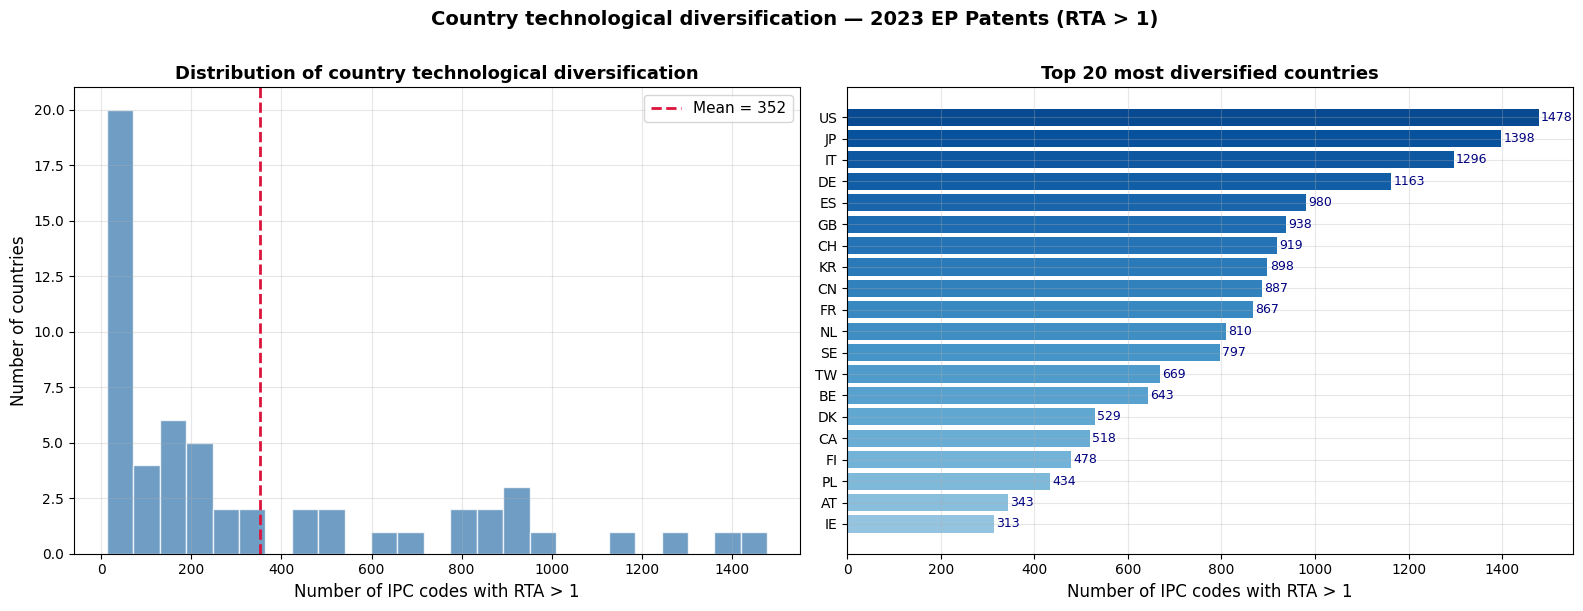

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(country_degrees, bins=25, color='steelblue', alpha=0.78, edgecolor='white')
axes[0].axvline(country_degrees.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Mean = {country_degrees.mean():.0f}')
axes[0].set_xlabel('Number of IPC codes with RTA > 1', fontsize=12)
axes[0].set_ylabel('Number of countries', fontsize=12)
axes[0].set_title('Distribution of country technological diversification', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)

top20c = df_countries.head(20)
colors_c = plt.cm.Blues(np.linspace(0.4, 0.9, 20))[::-1]
axes[1].barh(range(20), top20c['num_ipc'].values, color=colors_c)
axes[1].set_yticks(range(20))
axes[1].set_yticklabels(top20c['country'].values, fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel('Number of IPC codes with RTA > 1', fontsize=12)
axes[1].set_title('Top 20 most diversified countries', fontsize=13, fontweight='bold')
for i, v in enumerate(top20c['num_ipc'].values):
    axes[1].text(v + 5, i, str(v), va='center', fontsize=9, color='navy')

plt.suptitle('Country technological diversification — 2023 EP Patents (RTA > 1)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**Main insights on country diversification.**

Diversification here means how many distinct IPC technology codes a country has RTA > 1 in. A country with high diversification is specialised across many different technology areas and a country with low diversification is specialised in only a few.   

After applying the **RTA binarisation**, the **US (1,478 codes)**, **Japan (1,398)**, and **Italy (1,296)** come out as the most technologically diversified countries in the 2023 EP patent data.

Two things stand out here:

1. **The ranking is quite different from the raw patent counts.** Japan has the highest total number of patents, but it is only **second** when I look at diversification based on RTA. Italy has far fewer patents overall, but it ranks **third**. This suggests that Italy spreads its patenting activity across many different technology areas relative to its size. 

2. **The distribution is right-skewed.** This means that only a small number of countries have very high diversification, while most countries have lower values. This matters because, without proper normalisation, highly diversified countries would appear similar to many others just by chance, simply because they are linked to so many IPC codes.



### 3.2 Technology code ubiquity
- how many countries have RTA > 1 in each IPC code


In [55]:
print("Top 20 most ubiquitous IPC technology codes (RTA > 1):\n")
print(df_ipc_stats.head(20).to_string(index=False))

Top 20 most ubiquitous IPC technology codes (RTA > 1):

ipc_code  num_countries  total_patents
  G01N33             26           1057
  A61K31             24           1998
   A61K9             24            740
  G06Q10             23            776
  C07K14             23            600
   A61B5             23           1440
   H04L9             22           1042
  G06F21             21            903
  A61P31             20            539
  A61K47             20            638
   E04B1             19            105
   H02M1             19            426
  A61K35             19            442
  H04L67             19            474
  A61P25             19            522
   A61P1             19            268
   H02G3             19             85
  G06V10             19            475
   B01L3             18            205
   G06T7             18           1138


In [56]:
# I manually computed the WIPO descriptions for the top-20 most ubiquitous codes (the source can be found above)
TOP20_IPC_DESCRIPTIONS = {
    'G01N33': 'Biochemical & clinical analysis methods',
    'A61K31': 'Organic active pharmaceutical ingredients',
    'A61K9' : 'Drug delivery forms & formulations',
    'G06Q10': 'ICT for admin. & management',
    'C07K14': 'Proteins & peptide sequences (>20 aa)',
    'A61B5' : 'Physiological diagnostics & measurement',
    'H04L9' : 'Cryptography & network security protocols',
    'G06F21': 'Computer security & access control',
    'A61P31': 'Anti-infective agents (antivirals, antibiotics)',
    'A61K47': 'Pharmaceutical excipients & drug carriers',
    'E04B1' : 'Main building structures & walls',
    'H02M1' : 'Power electronics — converter details',
    'A61K35': 'Biotherapeutics & biological drug materials',
    'H04L67': 'Network application-layer services',
    'A61P25': 'Neurological & psychiatric drug treatments',
    'A61P1' : 'Drugs for alimentary tract & metabolism',
    'H02G3' : 'Installation of cables & conduits',
    'G06V10': 'Deep learning for visual pattern recognition',
    'B01L3' : 'Microfluidic & lab-on-chip apparatus',
    'G06T7' : 'Image analysis & computer vision',
}

top20_ipc = df_ipc_stats.head(20).copy()
top20_ipc['description'] = top20_ipc['ipc_code'].map(TOP20_IPC_DESCRIPTIONS).fillna('—')
top20_ipc['label'] = top20_ipc.apply(lambda r: f"{r['ipc_code']}: {r['description']}", axis=1)

print("Top 20 most ubiquitous IPC codes with WIPO descriptions:")
print(top20_ipc[['ipc_code','num_countries','description']].to_string(index=False))


Top 20 most ubiquitous IPC codes with WIPO descriptions:
ipc_code  num_countries                                     description
  G01N33             26         Biochemical & clinical analysis methods
  A61K31             24       Organic active pharmaceutical ingredients
   A61K9             24              Drug delivery forms & formulations
  G06Q10             23                     ICT for admin. & management
  C07K14             23           Proteins & peptide sequences (>20 aa)
   A61B5             23         Physiological diagnostics & measurement
   H04L9             22       Cryptography & network security protocols
  G06F21             21              Computer security & access control
  A61P31             20 Anti-infective agents (antivirals, antibiotics)
  A61K47             20       Pharmaceutical excipients & drug carriers
   E04B1             19                Main building structures & walls
   H02M1             19           Power electronics — converter details
  A61K3

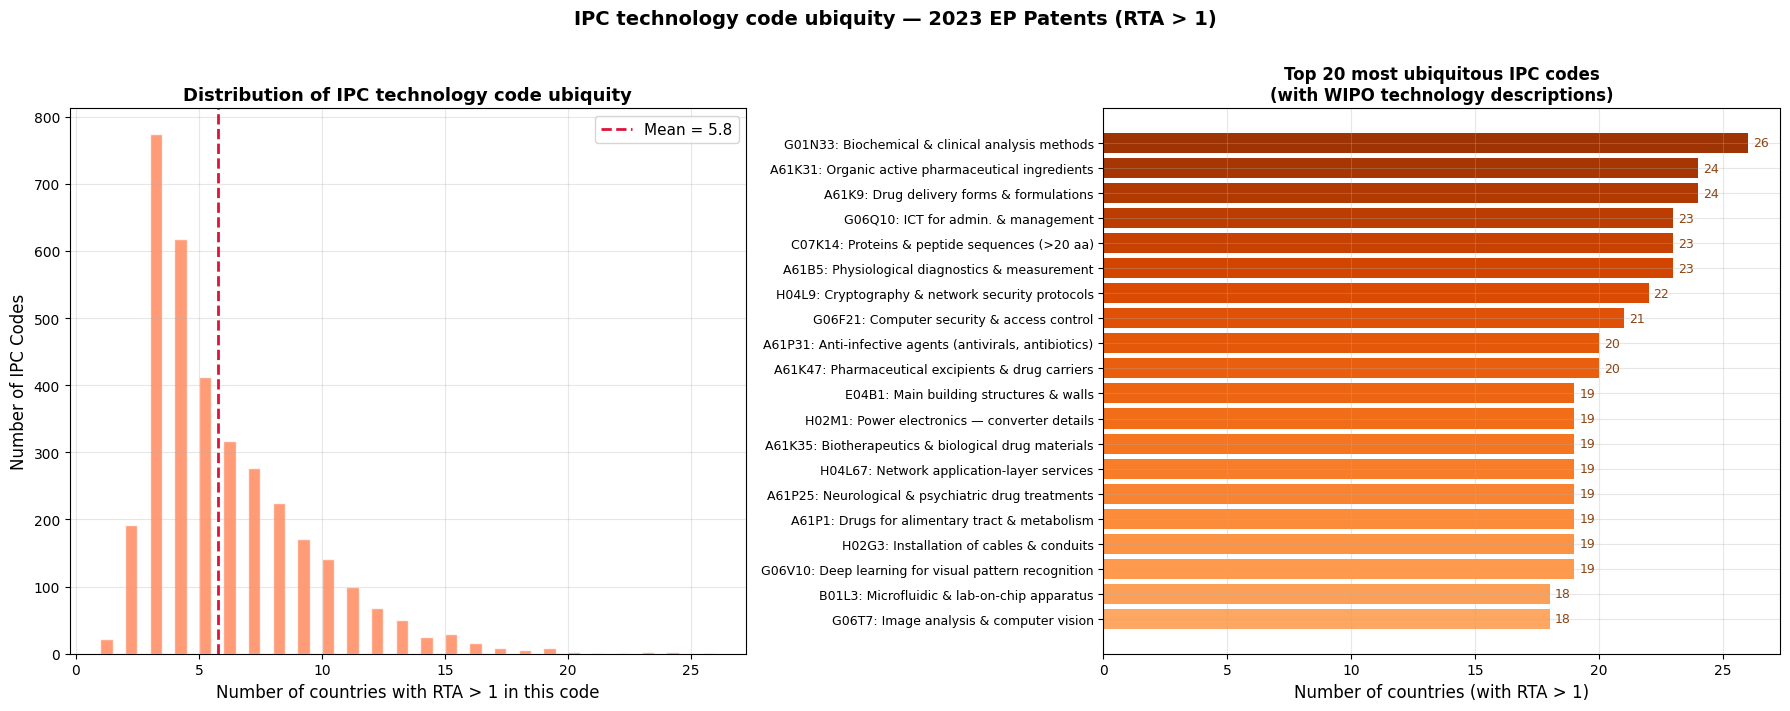

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].hist(ipc_degrees, bins=50, color='coral', alpha=0.78, edgecolor='white')
axes[0].axvline(ipc_degrees.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Mean = {ipc_degrees.mean():.1f}')
axes[0].set_xlabel('Number of countries with RTA > 1 in this code', fontsize=12)
axes[0].set_ylabel('Number of IPC Codes', fontsize=12)
axes[0].set_title('Distribution of IPC technology code ubiquity', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)

colors_ipc = plt.cm.Oranges(np.linspace(0.4, 0.9, 20))[::-1]
axes[1].barh(range(20), top20_ipc['num_countries'].values, color=colors_ipc)
axes[1].set_yticks(range(20))
axes[1].set_yticklabels(top20_ipc['label'].values, fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlabel('Number of countries (with RTA > 1)', fontsize=12)
axes[1].set_title('Top 20 most ubiquitous IPC codes\n(with WIPO technology descriptions)',
                  fontsize=12, fontweight='bold')
for i, v in enumerate(top20_ipc['num_countries'].values):
    axes[1].text(v + 0.2, i, str(v), va='center', fontsize=9, color='saddlebrown')

plt.suptitle('IPC technology code ubiquity — 2023 EP Patents (RTA > 1)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


**Main insights on IPC code ubiquity**

Ubiquity here means how many countries have RTA > 1 in a given IPC technology code. A ubiquitous technology is one where many countries are specialised. A niche technology is one where only one or two countries show up.   

**G01N33** (26 countries) — biochemical and clinical testing methods — tops the list. It appears in many countries because clinical diagnostics is an important research area worldwide and does not always require the same level of investment as heavier industrial technologies.

A clear **pharma and life sciences cluster** also appears near the top of the list. This includes codes such as **A61K31, A61K9, C07K14, A61B5, A61K47, A61K35, A61P31, A61P25, and A61P1**. These codes are mainly related to medicines, biotechnology, and medical research.

There is also a **digital and cybersecurity cluster**. Examples include **H04L9** (cryptography), **G06F21** (access control), **H04L67** (network services), **G06V10** (deep learning), and **G06T7** (image analysis).

The IPC degree distribution is also right-skewed: most codes are specialised to a few countries, and only a handful are globally ubiquitous.


### 3.3 Bipartite network summary 

In [58]:
print("=" * 62)
print("BIPARTITE NETWORK — SUMMARY STATISTICS (after RTA > 1)")
print("=" * 62)
print(f"\nNetwork size:")
print(f"Countries: {num_countries}")
print(f"IPC technology codes: {num_ipc}")
print(f"Total possible links: {num_countries * num_ipc:,}")
print(f"Active links (RTA > 1): {M.sum():,}")
print(f"Network density: {M.sum() / M.size:.4f}")
print(f"\nCountry statistics:")
print(f"Average diversification: {country_degrees.mean():.1f} IPC codes")
print(f"Std. deviation: {country_degrees.std():.1f}")
print(f"Most diversified: {df_countries.iloc[0]['country']} "
      f"({df_countries.iloc[0]['num_ipc']} codes)")
print(f"Least diversified: {df_countries.iloc[-1]['country']} "
      f"({df_countries.iloc[-1]['num_ipc']} codes)")
print(f"\nIPC code statistics:")
print(f"Average ubiquity: {ipc_degrees.mean():.2f} countries")
print(f"Std. deviation: {ipc_degrees.std():.2f}")
print(f"Most ubiquitous: {df_ipc_stats.iloc[0]['ipc_code']} "
      f"({df_ipc_stats.iloc[0]['num_countries']} countries)")
print("=" * 62)


BIPARTITE NETWORK — SUMMARY STATISTICS (after RTA > 1)

Network size:
Countries: 57
IPC technology codes: 3469
Total possible links: 197,733
Active links (RTA > 1): 20,089
Network density: 0.1016

Country statistics:
Average diversification: 352.4 IPC codes
Std. deviation: 399.4
Most diversified: US (1478 codes)
Least diversified: PR (13 codes)

IPC code statistics:
Average ubiquity: 5.79 countries
Std. deviation: 3.28
Most ubiquitous: G01N33 (26 countries)


*Network size:*
- The bipartite network connects 57 countries to 3,469 IPC technology codes. The maximum number of possible links between them would be 57 × 3,469 = 197,733 which would happen if every country was specialised in every technology, which is obviously unrealistic.

*Country statitics:*
- The average diversification is 352 IPC codes out of 3,469 possible, so the average country is genuinely specialised in about 10% of all technology codes. This is consistent with the overall density figure.
- The standard deviation (399) is larger than the mean (352), which is a strong signal that diversification is very unequal across countries. Some countries are highly diversified, many are not, and the distribution is skewed —-> a few countries pull the average up considerably.
- The most diversified country is the US with 1,478 codes —-> meaning the US has RTA > 1 in over 40% of all IPC codes. However, the US being most diversified does not mean it files the most patents (Japan does, with 49,238 records vs the US's 31,205). It means the US patents proportionally across the widest range of technology areas relative to its own portfolio size. In other words, the US is simultaneously active in energy storage, pharma, semiconductors, AI, aerospace, and many other fields at above-global-average rates.
- The least diversified country is PR (Puerto Rico) with only 13 codes. This makes sense as Puerto Rico files very few patents overall, and those it does file are likely concentrated in a narrow set of technology areas. With limited patent volume, it is statistically unlikely to achieve RTA > 1 in many codes. 

*IPC code statistics:*
- The average ubiquity is 5.79 countries out of 57 possible. So on average, any given IPC code is "claimed" as a specialisation by fewer than 6 countries. This means that most technologies are relatively niche, dominated by only a handful of countries in the bipartite network.
- The standard deviation (3.28) is again substantial relative to the mean, meaning ubiquity varies considerably across IPC codes. Some technologies are broadly shared, many are highly concentrated.
- The most ubiquitous IPC code is G01N33, appearing in 26 out of 57 countries. G01N33 covers biochemical and biological testing (diagnostic assays, immunoassays, detection of specific substances in biological fluids). The fact that nearly half of all countries have RTA > 1 here suggests that biomedical diagnostics is a broadly distributed technological competency: many countries, regardless of their overall patent volume or economic profile, have developed genuine strength in this area. This is somewhat expected for pharma and biotech, where research activity is widespread across academic and industrial settings in many countries.
- The fact that even the most ubiquitous code only appears in 26 out of 57 countries (45%) reinforces how sparse this network really is. There is no technology where all or even most countries are specialised.
                                                                                                                                  

Together these numbers tell me that the world's technological specialisation landscape is heterogeneous and concentrated: a few countries do a bit of everything, most countries focus on a few things, and most technologies are the domain of only a small group of specialists. 

### 3.4 Relationship between diversification and patent volume

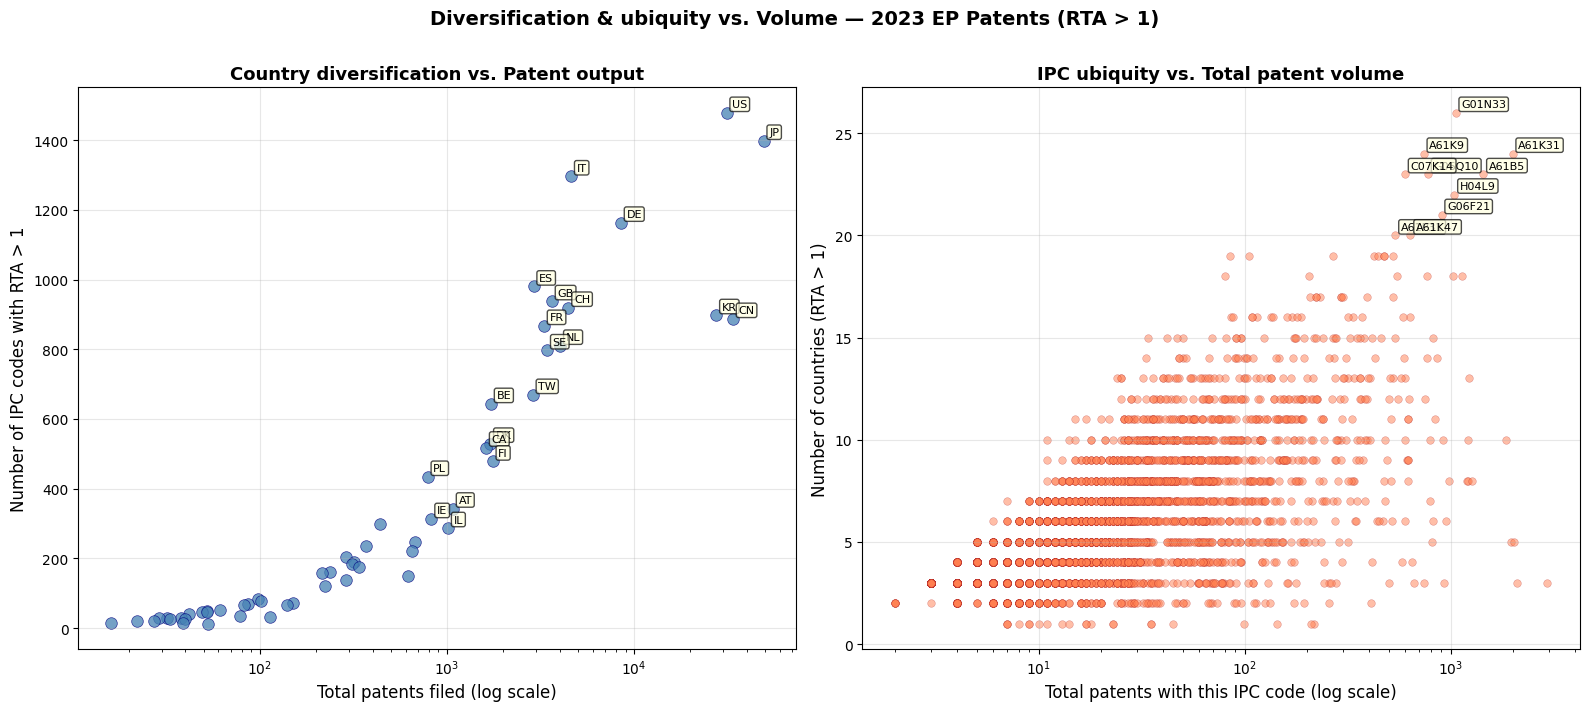

Country:  r(log patents, diversification) = 0.918, p = 8.25e-24
IPC code: r(log patents, ubiquity) = 0.683, p = 0.00e+00


In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

x1 = df_countries['total_patents'].values
y1 = df_countries['num_ipc'].values
axes[0].scatter(x1, y1, s=70, alpha=0.75, color='steelblue', edgecolors='navy', linewidth=0.5)
axes[0].set_xscale('log')
axes[0].set_xlabel('Total patents filed (log scale)', fontsize=12)
axes[0].set_ylabel('Number of IPC codes with RTA > 1', fontsize=12)
axes[0].set_title('Country diversification vs. Patent output', fontsize=13, fontweight='bold')
q70x = np.percentile(x1, 65); q70y = np.percentile(y1, 65)
for i, row in df_countries.iterrows():
    if row['total_patents'] >= q70x or row['num_ipc'] >= q70y:
        axes[0].annotate(row['country'], (row['total_patents'], row['num_ipc']),
                         xytext=(4,4), textcoords='offset points', fontsize=8,
                         bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', alpha=0.7))

x2 = df_ipc_stats['total_patents'].values
y2 = df_ipc_stats['num_countries'].values
axes[1].scatter(x2, y2, s=30, alpha=0.50, color='coral', edgecolors='firebrick', linewidth=0.3)
axes[1].set_xscale('log')
axes[1].set_xlabel('Total patents with this IPC code (log scale)', fontsize=12)
axes[1].set_ylabel('Number of countries (RTA > 1)', fontsize=12)
axes[1].set_title('IPC ubiquity vs. Total patent volume', fontsize=13, fontweight='bold')
for _, row in df_ipc_stats.head(10).iterrows():
    axes[1].annotate(row['ipc_code'], (row['total_patents'], row['num_countries']),
                     xytext=(4,4), textcoords='offset points', fontsize=8,
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='lightyellow', alpha=0.7))

plt.suptitle('Diversification & ubiquity vs. Volume — 2023 EP Patents (RTA > 1)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

r1, p1 = pearsonr(np.log10(x1 + 1), y1)
r2, p2 = pearsonr(np.log10(x2 + 1), y2)
print(f"Country:  r(log patents, diversification) = {r1:.3f}, p = {p1:.2e}")
print(f"IPC code: r(log patents, ubiquity) = {r2:.3f}, p = {p2:.2e}")


I used a **log scale** on the x-axis because patent counts vary a lot, from only a few to almost 50,000. In this way, I wanted to spread the data evenly across the full range, so that the difference between 100 and 1,000 patents takes up the same visual space as the difference between 1,000 and 10,000. This makes the relationship between patent volume and specialisation readable across all 57 countries (or all 3,469 IPC codes) at once.   

**Main insights:**

*Country diversification vs. patent output (r = 0.918, p ≈ 0):* 
- this plot shows a **very strong positive relationship**. Countries that file more patents overall also tend to be specialised in more IPC technology areas. The points follow a clear upward trend, although not perfectly. A few countries, such as **Italy** and **Spain**, sit above the main pattern, meaning they are more diversified than their total patent volume alone would suggest. 

*IPC code ubiquity vs. total patent volume (r = 0.683, p ≈ 0):*
- this plot also shows a **positive relationship**, but it is weaker and more scattered. IPC codes with more patents tend to appear in more countries, but the pattern is less tight than on the country side. Some technologies are highly concentrated in only a few countries, while others are common across many countries. This means that technology specialisation is more widely spread than country diversification, and that even smaller countries can still be important specialists in certain global technologies.

---
## Step 4: Naive network projection

I'll first compute the **naive co-occurrence projection** onto countries.
Two countries $i$ and $j$ are connected if they share at least one IPC code with $\text{RTA} > 1$:

$$W_{ij} = \sum_{t} M_{it} \cdot M_{jt} \qquad A_{ij} = 1 \text{ if } W_{ij} > 0$$

Even with the more selective RTA binarisation, countries with high diversification will share many IPC codes with almost everyone else, producing a near-fully connected network


In [60]:
W_naive = M @ M.T
np.fill_diagonal(W_naive, 0)

adj_naive = (W_naive > 0).astype(int)

G_naive = nx.from_numpy_array(adj_naive)
G_naive = nx.relabel_nodes(G_naive, {i: countries[i] for i in range(num_countries)})

n_naive = G_naive.number_of_edges()
d_naive = nx.density(G_naive)
poss    = num_countries * (num_countries - 1) // 2

print("Naive co-occurrence projection:")
print(f"  Nodes: {G_naive.number_of_nodes()}")
print(f"  Edges:  {n_naive:,}")
print(f"  Density: {d_naive:.4f}")
print(f"  Average degree: {2*n_naive/G_naive.number_of_nodes():.1f}")
print(f"  Connected components:{nx.number_connected_components(G_naive)}")
print(f"\n  → {100*d_naive:.1f}% of all country pairs are connected")

Naive co-occurrence projection:
  Nodes: 57
  Edges:  1,494
  Density: 0.9361
  Average degree: 52.4
  Connected components:1

  → 93.6% of all country pairs are connected


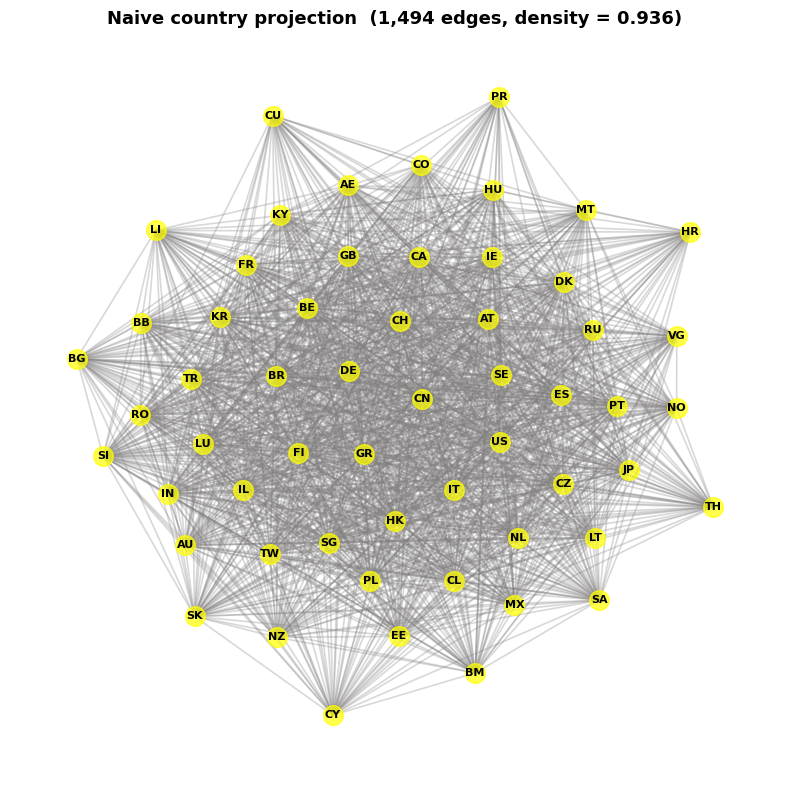

In [61]:
plt.figure(figsize=(8, 8))
pos_naive = nx.spring_layout(G_naive, seed=42, k=0.5)

nx.draw_networkx_nodes(G_naive, pos_naive, node_size=200, node_color='yellow', alpha=0.7)
nx.draw_networkx_edges(G_naive, pos_naive, edge_color="#827F7F",  alpha=0.30,  width=1.2)
nx.draw_networkx_labels(G_naive, pos_naive, font_size=8, font_weight='bold', font_color='black')

plt.title(f"Naive country projection  ({n_naive:,} edges, density = {d_naive:.3f})",
          fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


Even after applying RTA binarisation, the naive projection still creates an very dense network: it keeps 1,494 edges with a density of 0.936, which means that **93.6% of all possible country pairs are connected**. This makes the network look like one dense clump, both in the graph visualisation and in the adjacency matrix, with almost no clear structure. The reason is the **degree heterogeneity problem**: highly diversified countries (like the US) are connected to so many IPC codes that they will automatically share some of them with almost every other country, even when there is no truly meaningful similarity. As explained by **Saracco et al. (2017)**, these are mostly spurious co-occurrences, caused by broad portfolios rather than real overlap in technological specialisation. This matters because a network where almost everything is connected is not useful for answering the research question: it does not allow us to clearly detect communities, bridges, or meaningful patterns of similarity, so I need a **statistical null model** to separate genuine links from accidental ones.

---
## Step 5: Bipartite configuration model (BiCM) validated projection


In [62]:
# Applying the BiCM projection to the matrix M

print(f"Matrix: {num_countries} countries × {num_ipc} IPC codes")
print(f"Active links in M: {M.sum():,} (density {M.sum()/M.size:.4f})")

myGraph = BipartiteGraph()
myGraph.set_biadjacency_matrix(M)

myGraph.compute_projection(
    rows=True,
    alpha=0.05, # more appropriate for a smaller dataset
    approx_method='poisson',
    threads_num=1,
    progress_bar=True
)

rows_edges = myGraph.get_rows_projection(fmt='edgelist')
n_bicm = len(rows_edges)

print(f"BiCM projection complete")
print(f"  Significant country–country links: {n_bicm}")
print(f"  Density: {2*n_bicm/(num_countries*(num_countries-1)):.4f}")
print(f"  Reduction from naive: {100*(1 - 2*n_bicm/adj_naive.sum()):.1f}%")
print(f"  Sparsification factor: {n_naive/max(n_bicm,1):.1f}×")


Matrix: 57 countries × 3469 IPC codes
Active links in M: 20,089 (density 0.1016)
First I have to compute the BiCM. Computing...
max rows error = 4.160938260611147e-11
max columns error = 3.552713678800501e-14
total error = 2.942996957244759e-10
Solver converged.


100%|██████████| 57/57 [00:00<00:00, 1442.31it/s]

BiCM projection complete
  Significant country–country links: 73
  Density: 0.0457
  Reduction from naive: 95.1%
  Sparsification factor: 20.5×


In [63]:
# Building the BiCM validated graph
G_val = nx.Graph()
G_val.add_nodes_from(range(num_countries))
G_val.add_edges_from(rows_edges)
G_val = nx.relabel_nodes(G_val, {i: countries[i] for i in range(num_countries)})

n_val          = G_val.number_of_edges()
d_val          = nx.density(G_val)
isolated_nodes = sorted(nx.isolates(G_val))
comps_val      = sorted(nx.connected_components(G_val), key=len, reverse=True)

# Build connected subgraph (non-isolated countries only)
connected_nodes = [n for n in G_val.nodes() if G_val.degree(n) > 0]
G_connected     = G_val.subgraph(connected_nodes).copy()

removed      = n_naive - n_val
pct_removed  = 100 * removed / n_naive
spars_factor = n_naive / max(n_val, 1)

print("BiCM validated network:")
print(f"  Nodes: {G_val.number_of_nodes()}")
print(f"  Edges: {n_val}")
print(f"  Density: {d_val:.4f}")
print(f"  Components: {nx.number_connected_components(G_val)}")
print(f"  Component sizes: {[len(c) for c in comps_val[:6]]}")
print(f"  Isolated countries: {len(isolated_nodes)}")
print(f"  Connected countries: {G_connected.number_of_nodes()}")
print(f"  → {isolated_nodes}")


BiCM validated network:
  Nodes: 57
  Edges: 73
  Density: 0.0457
  Components: 25
  Component sizes: [32, 2, 1, 1, 1, 1]
  Isolated countries: 23
  Connected countries: 34
  → ['AT', 'BE', 'CH', 'CN', 'CO', 'CY', 'DE', 'DK', 'EE', 'ES', 'GB', 'HR', 'IT', 'JP', 'KR', 'LU', 'NL', 'NZ', 'PR', 'SK', 'TH', 'TR', 'US']


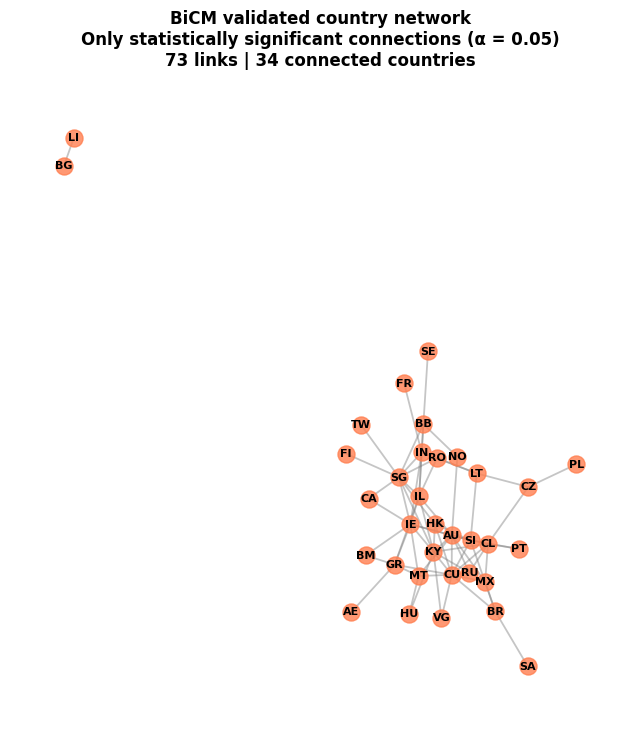

In [64]:
# Visualizing the BiCM validated network with the connected countries only
# those 23 isolated countries are excluded from this figure

plt.figure(figsize=(8, 8))
pos_val = nx.spring_layout(G_connected, seed=2, k=0.8, iterations=300, scale=0.75, center=(0, 0.15))

nx.draw_networkx_nodes(G_connected, pos_val, node_size=150, node_color='coral', alpha=0.8)
nx.draw_networkx_edges(G_connected, pos_val, edge_color='gray', alpha=0.45, width=1.3)
nx.draw_networkx_labels(G_connected, pos_val, font_size=8, font_weight='bold')

plt.title(
    f"BiCM validated country network\n"
    f"Only statistically significant connections (α = 0.05)\n"
    f"{n_val} links | {G_connected.number_of_nodes()} connected countries",
    fontsize=12, fontweight='bold', pad=12
)

plt.axis('off')
plt.subplots_adjust(top=0.9, bottom=0.1)  
plt.show()

**Main insights**

In the BiCM validated network, each node is a country and each edge means that two countries share **more technology specialisation than we would expect by chance** after RTA binarisation. After applying BiCM, only **73 significant links** are left, and the network density falls from **0.936 to 0.046**. This means that **95.1% of the links are removed**, or in other words, the network becomes about **20 times sparser**. This is actually the expected result: the naive network was almost fully connected because large countries with very broad patent portfolios naturally shared many IPC codes with others. BiCM removes these expected overlaps and keeps only the links that are really unusual. This is why **23 out of 57 countries** become **isolated**, including Germany, the US, Japan, South Korea, Great Britain, China, Italy, Spain, and the Netherlands. These countries patent in so many technology areas that their overlap with others is already expected, so there is no extra similarity left to produce a significant link. The **34 countries that stay connected** are mostly smaller and more focused patenting countries, where the shared technology patterns are more informative.


### Naive vs. BiCM 

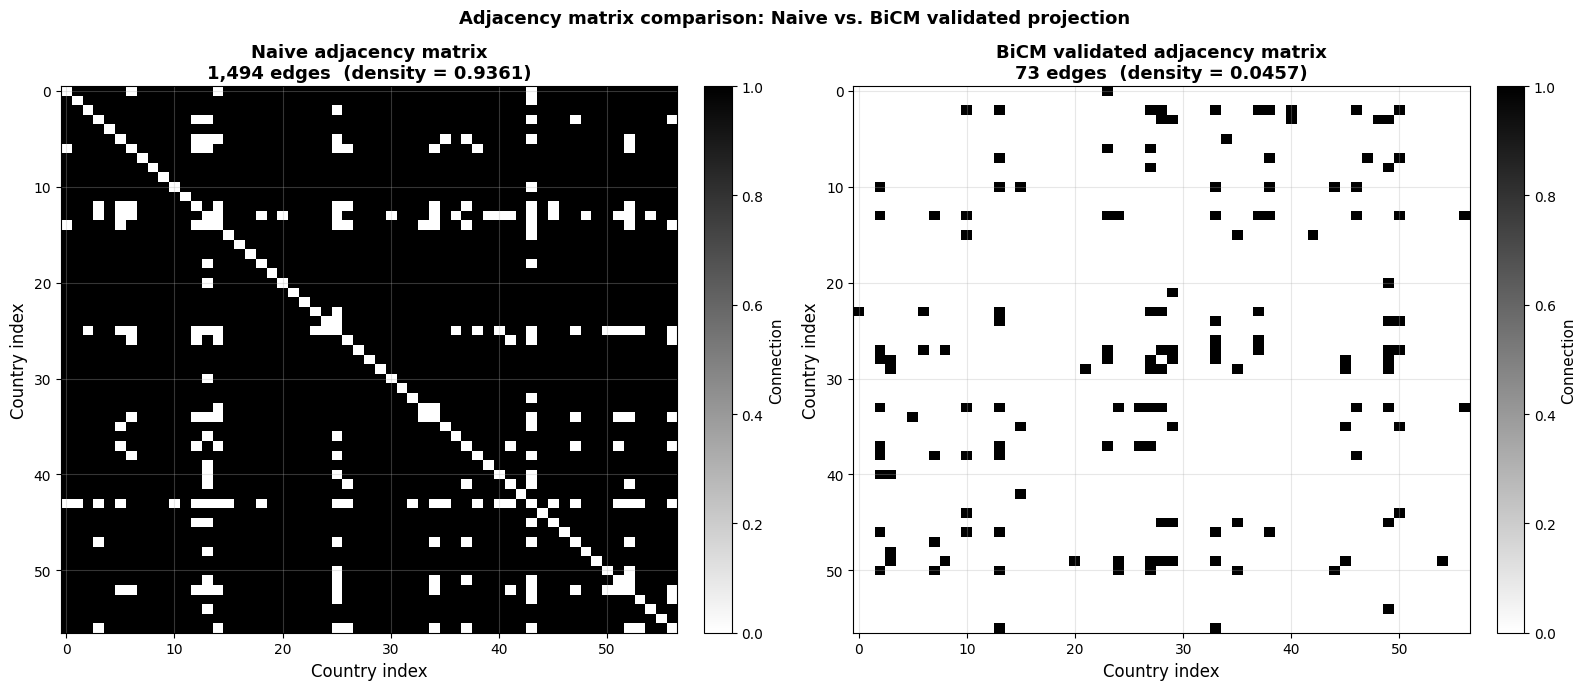


ADJACENCY MATRIX COMPARISON
Naive projection:
- Total edges: 1,494
- Density: 0.9361
- Percentage of possible edges: 93.6%

BiCM validated projection  (α = 0.05, Poisson approximation):
- Total edges: 73
- Density: 0.0457
- Percentage of possible edges: 4.6%

Reduction:
- Edges removed: 1,421
- Percentage removed: 95.1%
- Sparsification factor: 20.5×


In [65]:
# Adjacency matrix comparison: naive vs. BiCM validated
# here, I'll build the BiCM adjacency matrix, compare it to the naive one and I'll plot both side by side
# I'll also print a short summary showing how much sparser the validated network is after filtering out the non-significant links

bicm_adj = np.zeros((num_countries, num_countries), dtype=int)
for i, j in rows_edges:
    bicm_adj[i, j] = 1
    bicm_adj[j, i] = 1

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

im1 = axes[0].imshow(adj_naive, cmap='binary', aspect='auto', interpolation='nearest')
axes[0].set_xlabel('Country index', fontsize=12)
axes[0].set_ylabel('Country index', fontsize=12)
axes[0].set_title(
    f'Naive adjacency matrix\n{n_naive:,} edges  (density = {n_naive/poss:.4f})',
    fontsize=13, fontweight='bold')
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04).set_label('Connection', fontsize=11)

im2 = axes[1].imshow(bicm_adj, cmap='binary', aspect='auto', interpolation='nearest')
axes[1].set_xlabel('Country index', fontsize=12)
axes[1].set_ylabel('Country index', fontsize=12)
axes[1].set_title(
    f'BiCM validated adjacency matrix\n{n_val} edges  (density = {d_val:.4f})',
    fontsize=13, fontweight='bold')
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04).set_label('Connection', fontsize=11)

plt.suptitle('Adjacency matrix comparison: Naive vs. BiCM validated projection',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("ADJACENCY MATRIX COMPARISON")
print("=" * 60)
print(f"Naive projection:")
print(f"- Total edges: {n_naive:,}")
print(f"- Density: {n_naive/poss:.4f}")
print(f"- Percentage of possible edges: {100*n_naive/poss:.1f}%")
print()
print(f"BiCM validated projection  (α = 0.05, Poisson approximation):")
print(f"- Total edges: {n_val}")
print(f"- Density: {d_val:.4f}")
print(f"- Percentage of possible edges: {100*d_val:.1f}%")
print()
print(f"Reduction:")
print(f"- Edges removed: {removed:,}")
print(f"- Percentage removed: {pct_removed:.1f}%")
print(f"- Sparsification factor: {spars_factor:.1f}×")
print("=" * 60)


**Main insights**

The side-by-side adjacency matrices make the difference between the two projections immediately visible. The **naive matrix** on the left is almost completely black — almost every country pair is connected, and the plot is filled solid. The **BiCM validated matrix** on the right is almost entirely white, with only a small scatter of black dots. The countries are listed in alphabetical order, so the dots look randomly placed, but each one represents a statistically significant technology co-specialisation link that survived the null model test. The contrast between the two matrices shows the filtering effect of BiCM in the clearest possible way.

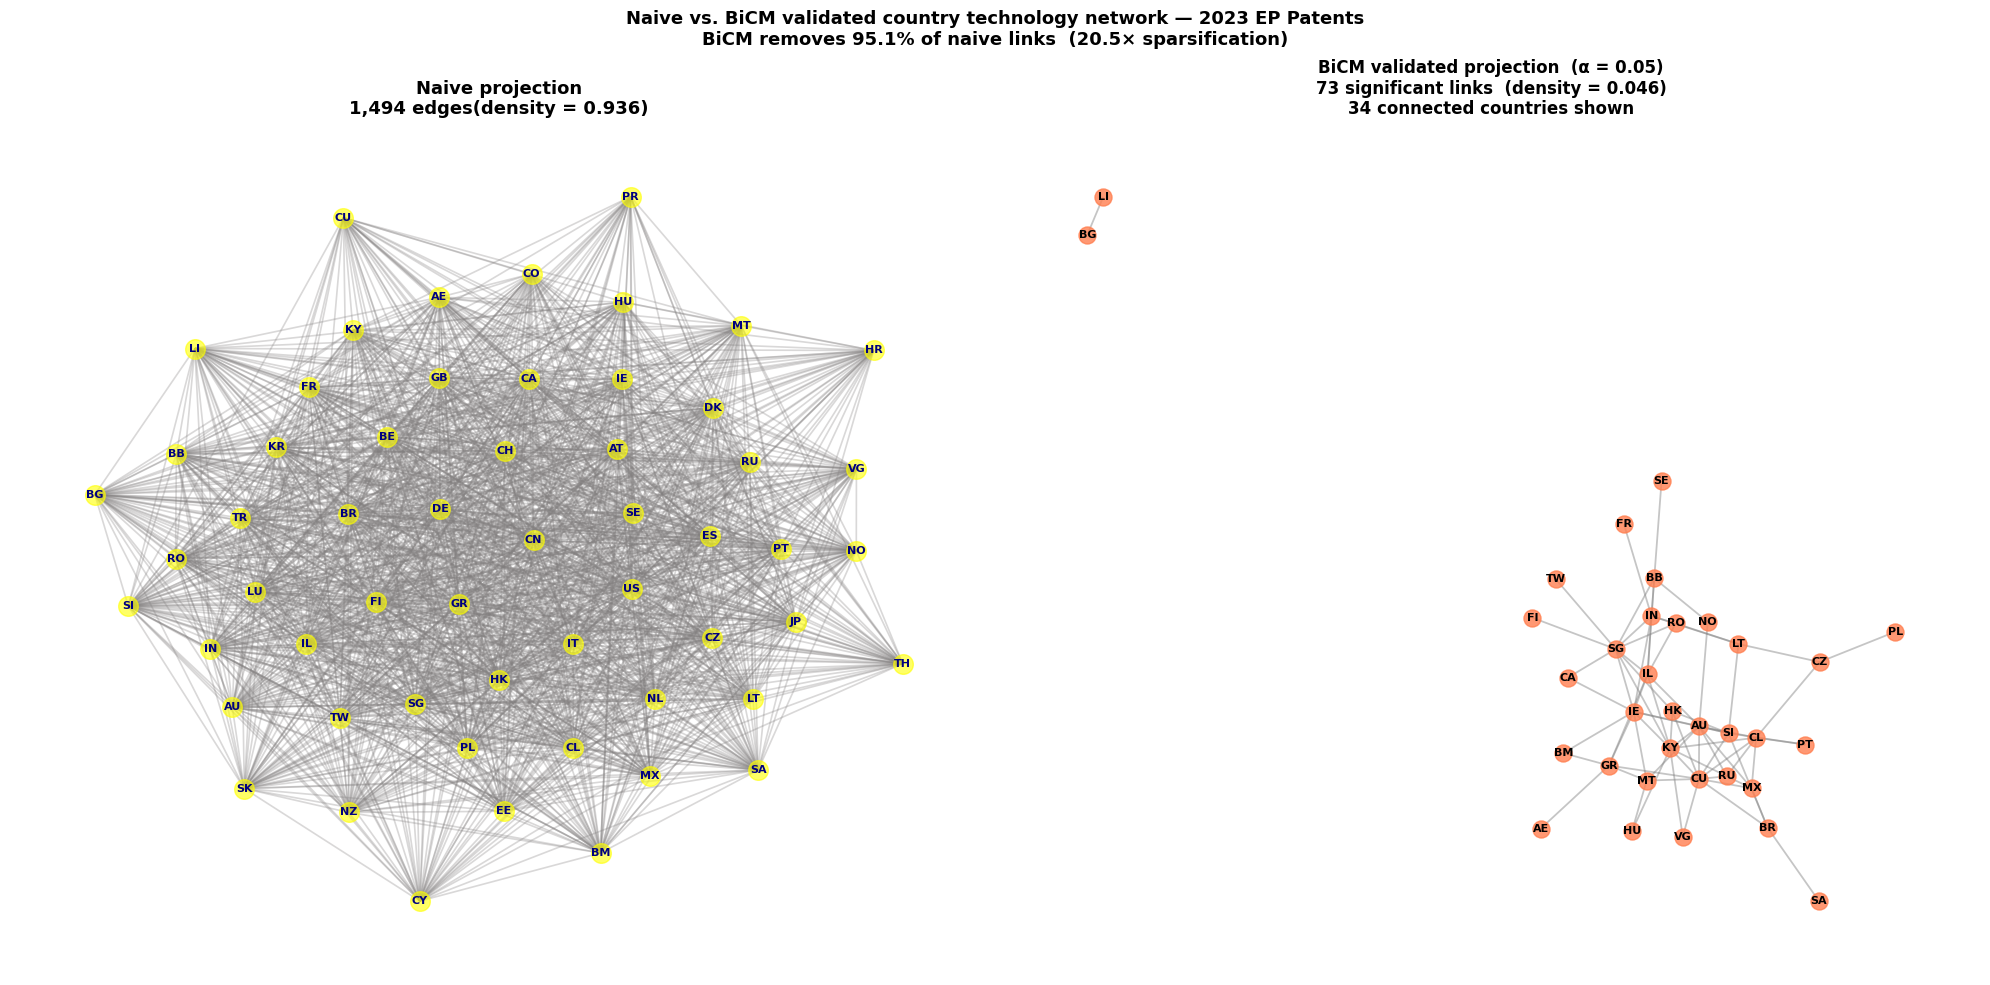

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Naive network
ax = axes[0]
nx.draw_networkx_nodes(G_naive, pos_naive, ax=ax, node_size=200, node_color='yellow', alpha=0.6)
nx.draw_networkx_edges(G_naive, pos_naive, ax=ax, edge_color="#827F7F",  alpha=0.30,  width=1.2)
nx.draw_networkx_labels(G_naive, pos_naive, ax=ax, font_size=8, font_weight='bold',
                        font_color='navy')
ax.set_title(f"Naive projection\n{G_naive.number_of_edges():,} edges"
             f"(density = {nx.density(G_naive):.3f})",
             fontsize=13, fontweight='bold')
ax.axis('off')

# BiCM validated network (connected countries only)
ax = axes[1]

nx.draw_networkx_nodes(G_connected, pos_val, ax=ax, node_size=150, node_color='coral', alpha=0.8)
nx.draw_networkx_edges(G_connected, pos_val, ax=ax, edge_color='gray', alpha=0.45, width=1.3)
nx.draw_networkx_labels(G_connected, pos_val, ax=ax, font_size=8, font_weight='bold')

ax.set_title(f"BiCM validated projection  (α = 0.05)\n"
             f"{G_val.number_of_edges()} significant links  (density = {d_val:.3f})\n"
             f"{G_connected.number_of_nodes()} connected countries shown",
             fontsize=12, fontweight='bold')
ax.axis('off')

plt.suptitle(f"Naive vs. BiCM validated country technology network — 2023 EP Patents\n"
             f"BiCM removes {pct_removed:.1f}% of naive links  ({spars_factor:.1f}× sparsification)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()



**Main insights**

The side-by-side network plots show the same result in a different way. The **naive projection** on the left is a dense, cluttered tangle where every country connects to almost every other — there is no visible structure, just a ball of edges. The **BiCM validated projection** on the right shows only the 34 connected countries with a much sparser set of links. There are clear gaps, a few more peripheral nodes, and the beginning of a cluster structure. This is the network we use for community detection in the next step.

---
## Step 6: Community Detection

I'll detect communities in the BiCM validated network using the **Louvain algorithm**.

The algorithm maximises **modularity** $Q$:

$$Q = \frac{1}{2m} \sum_{ij} \left[ A_{ij} - \frac{k_i k_j}{2m} \right] \delta(c_i, c_j)$$

A community in this network is a group of countries that share significantly more technology overlap among themselves than with countries outside the group.

I'll run community detection on the **connected countries only** (the 34 non-isolated countries)


In [67]:
print("Community detection using the Louvain algorithm")
print("=" * 55)
print(f"Connected countries (non-isolated): {G_connected.number_of_nodes()}")
print(f"Edges in connected subgraph: {G_connected.number_of_edges()}")

try:
    communities = nx.algorithms.community.louvain_communities(G_connected, seed=42)
    method_name = "Louvain"
except AttributeError:
    communities = list(nx.algorithms.community.greedy_modularity_communities(G_connected))
    method_name = "Greedy Modularity (fallback)"

partition = {}
for comm_id, comm in enumerate(communities):
    for node in comm:
        partition[node] = comm_id

num_communities = len(communities)
modularity      = nx.algorithms.community.quality.modularity(G_connected, communities)

print(f"Algorithm: {method_name}")
print(f"Communities: {num_communities}")
print(f"Modularity Q: {modularity:.4f}")
print()

community_sizes = Counter(partition.values())
print("Community sizes:")
for comm_id in sorted(community_sizes.keys()):
    print(f"  Community {comm_id}: {community_sizes[comm_id]} countries")


Community detection using the Louvain algorithm
Connected countries (non-isolated): 34
Edges in connected subgraph: 73
Algorithm: Louvain
Communities: 4
Modularity Q: 0.3736

Community sizes:
  Community 0: 6 countries
  Community 1: 2 countries
  Community 2: 14 countries
  Community 3: 12 countries


In [68]:
# Show community members
community_members = defaultdict(list)
for country, comm_id in partition.items():
    community_members[comm_id].append(country)

print("Community members:\n")
for comm_id in sorted(community_members.keys(), key=lambda c: -len(community_members[c])):
    members = sorted(community_members[comm_id])
    print(f"Community {comm_id} ({len(members)} countries):")
    for i in range(0, len(members), 10):
        print(f"  {', '.join(members[i:i+10])}")
    print()

print("Isolated countries (not in any community):")
print(f"  {sorted(isolated_nodes)}")


Community members:

Community 2 (14 countries):
  BB, CA, CZ, FI, FR, IL, IN, LT, NO, PL
  RO, SE, SG, TW

Community 3 (12 countries):
  AU, BR, CL, CU, HK, KY, MX, PT, RU, SA
  SI, VG

Community 0 (6 countries):
  AE, BM, GR, HU, IE, MT

Community 1 (2 countries):
  BG, LI

Isolated countries (not in any community):
  ['AT', 'BE', 'CH', 'CN', 'CO', 'CY', 'DE', 'DK', 'EE', 'ES', 'GB', 'HR', 'IT', 'JP', 'KR', 'LU', 'NL', 'NZ', 'PR', 'SK', 'TH', 'TR', 'US']


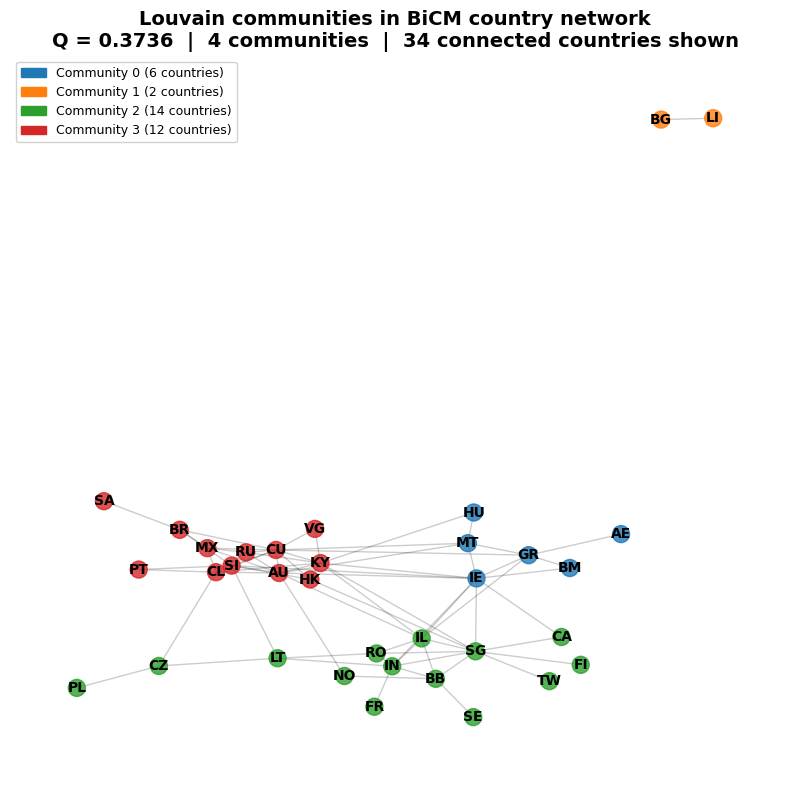

In [69]:
# Visualize communities
# I'll use a weighted spring layout to help same-community countries cluster visually:
# intra-community edges get weight=4.0, inter-community edges get weight=0.5
# This nudges the spring algorithm to pull community members together
# The actual graph, communities, and modularity are unchanged

G_layout = G_connected.copy()
for u, v in G_layout.edges():
    G_layout[u][v]['weight'] = 4.0 if partition[u] == partition[v] else 0.5

pos_comm = nx.spring_layout(G_layout, seed=42, k=1.5, weight='weight', iterations=500)

colors = list(mcolors.TABLEAU_COLORS.values())
if num_communities > len(colors):
    colors = [plt.cm.tab20(i / num_communities) for i in range(num_communities)]

node_colors = [colors[partition[node] % len(colors)] for node in G_connected.nodes()]

plt.figure(figsize=(8, 8))
nx.draw_networkx_nodes(G_connected, pos_comm, node_size=150,
                       node_color=node_colors, alpha=0.8)
nx.draw_networkx_edges(G_connected, pos_comm, alpha=0.2, width=1.0)
nx.draw_networkx_labels(G_connected, pos_comm, font_size=10, font_weight='bold')

legend_patches = [
    mpatches.Patch(color=colors[cid % len(colors)],
                   label=f'Community {cid} ({community_sizes[cid]} countries)')
    for cid in sorted(community_sizes.keys())
]
plt.legend(handles=legend_patches, loc='upper left', fontsize=9, framealpha=0.9)

plt.title(
    f"Louvain communities in BiCM country network\n"
    f"Q = {modularity:.4f}  |  {num_communities} communities  |  "
    f"{G_connected.number_of_nodes()} connected countries shown",
    fontsize=14, fontweight='bold'
)
plt.axis('off')
plt.tight_layout()
plt.show()


In [70]:
# For each community, I'll look at which IPC codes are shared by the most
# member countries (RTA > 1). This will tell me what technology areas are
# driving the community structure

community_members = defaultdict(list)
for country, comm_id in partition.items():
    community_members[comm_id].append(country)

ipc_section_labels = {
    'A': 'Human Necessities (pharma, food, medical)',
    'B': 'Operations & Transport (manufacturing, separation)',
    'C': 'Chemistry & Metallurgy',
    'D': 'Textiles & Paper',
    'E': 'Fixed Constructions',
    'F': 'Mechanical Engineering',
    'G': 'Physics (computing, optics, measurement)',
    'H': 'Electricity (electronics, telecom, energy)',
}

for comm_id in sorted(community_members.keys(), key=lambda c: -len(community_members[c])):
    members = sorted(community_members[comm_id])
    print(f"\nCommunity {comm_id}  ({len(members)} countries: {', '.join(members)})")
    print("-" * 55)

    # Get the row indices in the countries list for community members
    comm_indices = [countries.index(c) for c in members]

    # Extract the rows of M for these countries
    # M[i, j] = 1 if country i has RTA > 1 in IPC code j
    comm_M = M[comm_indices, :]

    # For each IPC code, count how many community members have RTA > 1
    shared_counts = comm_M.sum(axis=0)

    # Top 10 most shared IPC codes (shared by at least 2 members)
    top_idx = np.argsort(shared_counts)[::-1][:10]
    print(f"Top 10 most shared IPC codes:")
    for idx in top_idx:
        if shared_counts[idx] >= 2:
            ipc = ipc_codes[idx]
            section_desc = ipc_section_labels.get(ipc[0], 'Other')
            print(f"    {ipc:8s}  {int(shared_counts[idx]):2d}/{len(members)} members  |  Section {ipc[0]}: {section_desc}")

    # Count how many shared IPC codes fall into each section
    section_totals = Counter()
    for idx in range(len(ipc_codes)):
        if shared_counts[idx] >= 2:
            section_totals[ipc_codes[idx][0]] += 1

    print(f"\nIPC section summary (how many shared codes per section):")
    for sec, count in section_totals.most_common():
        print(f"Section {sec}: {count:4d} codes | {ipc_section_labels.get(sec, 'Other')}")


Community 2  (14 countries: BB, CA, CZ, FI, FR, IL, IN, LT, NO, PL, RO, SE, SG, TW)
-------------------------------------------------------
Top 10 most shared IPC codes:
    H04L67    10/14 members  |  Section H: Electricity (electronics, telecom, energy)
    H04L9     10/14 members  |  Section H: Electricity (electronics, telecom, energy)
    G06F21    10/14 members  |  Section G: Physics (computing, optics, measurement)
    G06V40    10/14 members  |  Section G: Physics (computing, optics, measurement)
    G06V10    10/14 members  |  Section G: Physics (computing, optics, measurement)
    H04L47     9/14 members  |  Section H: Electricity (electronics, telecom, energy)
    G01S19     9/14 members  |  Section G: Physics (computing, optics, measurement)
    G01N27     8/14 members  |  Section G: Physics (computing, optics, measurement)
    G06F16     8/14 members  |  Section G: Physics (computing, optics, measurement)
    H04L69     8/14 members  |  Section H: Electricity (electronics

**Main insights**

The Louvain algorithm finds **4 communities** among the 34 connected countries, with **modularity Q = 0.374**. The output above shows what technology areas bring each community together by looking at which IPC codes are shared by the most member countries (with RTA > 1)

**`Community 2 (14 countries: BB, CA, CZ, FI, FR, IL, IN, LT, NO, PL, RO, SE, SG, TW): Digital & computing cluster`**

The most shared IPC codes in this community are concentrated in digital technologies: H04L67 (network services and cloud), H04L9 (cryptographic protocols), G06F21 (security and access control), and G06V10 (image recognition and deep learning). These codes are shared by 10 out of 14 members. Looking at the section summary, the community has a broad industrial base (Section B — operations and manufacturing), but its most concentrated co-specialisations are in Sections G (physics/computing) and H (electronics/telecoms). This is a geographically diverse group. It includes Nordic countries, Central and Eastern European economies, and advanced smaller economies from Asia and North America. What the data shows is that these countries share a distinctive digital and computing fingerprint that is strong enough to generate statistically significant BiCM links. 

**`Community 3 (12 countries: AU, BR, CL, CU, HK, KY, MX, PT, RU, SA, SI, VG): Pharma & biotech cluster`**

This community has the clearest technology signature of the four. The most shared IPC codes are almost entirely pharmaceutical and biomedical: A61P25 (nervous system drugs), C07K14 (peptides), A61K31 (medicinal preparations), G01N33 (biochemical analysis), C12N15 (genetic engineering), and A61P31 (anti-infectives). These are shared by 7–9 out of 12 members. The section summary shows Sections A (pharma/medical) and C (chemistry/biotech) together dominate, followed by G (computing/measurement). This is perhaps the most surprising finding of the whole analysis. This community looks geographically like a mix of Latin American, offshore, and emerging economies. But the BiCM reveals that what connects them in the validated network is a shared specialisation in pharmaceutical and biological technologies. A possible explanation is that several of these countries have concentrated patent activity in a relatively narrow set of biotech and pharma IPC codes, which makes their co-specialisations statistically significant beyond what degree alone would predict.

**`Community 0 (6 countries: AE, BM, GR, HU, IE, MT): Pharma & tech bridge`**

The top shared IPC codes here include A61K31 (medicinal preparations, shared by 5 of 6 members), A61B17 (surgical instruments), G06N20 (machine learning), and G01N33 (biochemical analysis). The section summary shows Sections G (physics/computing) and A (pharma/medical) as roughly equal, followed by smaller contributions from B and C. This small group bridges pharma and computing specialisations. Ireland in particular is a well-known for pharmaceutical company registrations, which likely contributes to the A-section signal.

**`Community 1 (2 countries: BG, LI): Construction materials pair`**

This is the smallest and most specific community. The only IPC codes shared by both Bulgaria and Liechtenstein are in Sections C and E: C04B28, C04B14 (cement and building materials), E04B1 and E04F13 (building construction). This is a very narrow and specific co-specialisation in construction-related technologies. It's a direct evidence of a genuine niche overlap, not a broad similarity.


All four communities are made up of smaller or mid-sized patent filers. The major patent powers (JP, CN, US, KR, DE, GB, IT, ES, NL) are all isolated because their portfolios are so broad that the BiCM expects them to overlap with almost everyone, leaving no "surprising" co-specialisations. 

---
## Step 7: Network metrics comparison


In [71]:
# Comparison table (Naive vs. BiCM)

comparison = pd.DataFrame({
    'Metric': ['Nodes','Edges','Density','Avg. Degree','Components'],
    'Naive': [
        G_naive.number_of_nodes(),
        G_naive.number_of_edges(),
        f"{nx.density(G_naive):.4f}",
        f"{2*G_naive.number_of_edges()/G_naive.number_of_nodes():.1f}",
        nx.number_connected_components(G_naive)
    ],
    'BiCM validated': [
        G_val.number_of_nodes(),
        G_val.number_of_edges(),
        f"{nx.density(G_val):.4f}",
        f"{2*G_val.number_of_edges()/max(G_val.number_of_nodes(),1):.1f}",
        nx.number_connected_components(G_val)
    ]
})
print("Naive vs. BiCM validated projection: key network metrics\n")
print(comparison.to_string(index=False))


Naive vs. BiCM validated projection: key network metrics

     Metric  Naive BiCM validated
      Nodes     57             57
      Edges   1494             73
    Density 0.9361         0.0457
Avg. Degree   52.4            2.6
 Components      1             25


**Main insights:**

In the naive network, almost everything is connected: it has **1,494 edges**, a very high **density of 0.9361**, an **average degree of 52.4**, and only **1 connected component**. This means the network is almost full, so it is difficult to see any meaningful structure. After applying BiCM, the network becomes much sparser, with only **73 edges**, a **density of 0.0457**, and an **average degree of 2.6**. The number of **components increases from 1 to 25**, meaning the validated network breaks into many smaller parts. Overall, this suggests that the naive projection mostly captures noise, while the BiCM validated projection keeps only the more meaningful links.

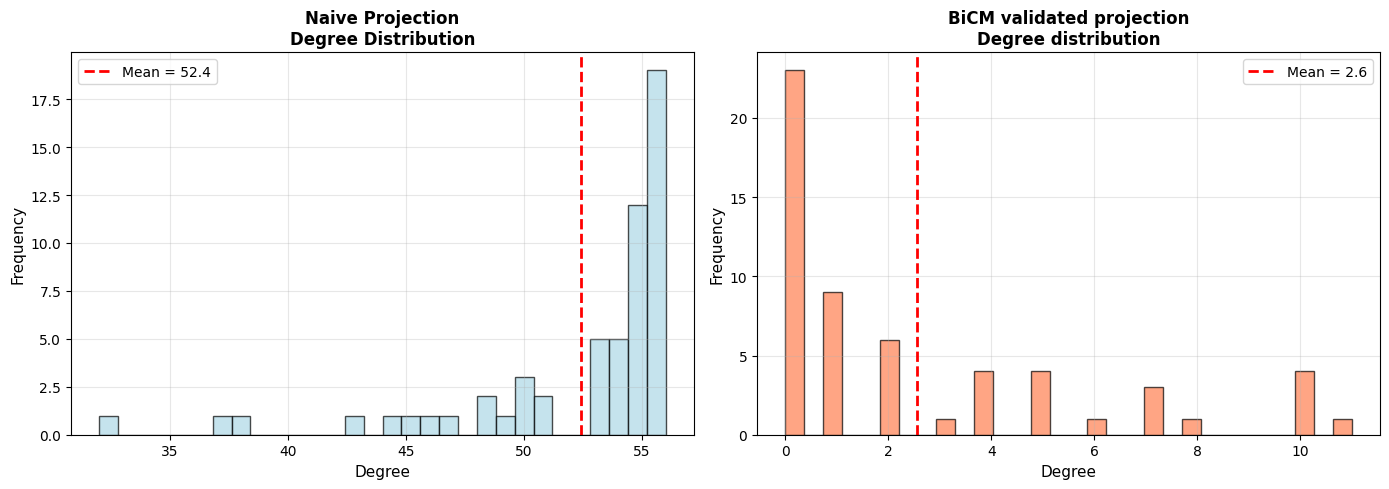

In [72]:
# Degree distribution comparison 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

degrees_naive = [d for n, d in G_naive.degree()]
axes[0].hist(degrees_naive, bins=30, color='lightblue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Degree', fontsize=11); axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Naive Projection\nDegree Distribution', fontsize=12, fontweight='bold')
axes[0].axvline(np.mean(degrees_naive), color='red', linestyle='--', linewidth=2,
                label=f'Mean = {np.mean(degrees_naive):.1f}')
axes[0].legend(); axes[0].grid(alpha=0.3)

degrees_bicm = [d for n, d in G_val.degree()]
axes[1].hist(degrees_bicm, bins=30, color='coral', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Degree', fontsize=11); axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('BiCM validated projection\nDegree distribution', fontsize=12, fontweight='bold')
axes[1].axvline(np.mean(degrees_bicm), color='red', linestyle='--', linewidth=2,
                label=f'Mean = {np.mean(degrees_bicm):.1f}')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Main insights**

The **naive degree distribution** is heavily concentrated at the high end, with most countries having degrees around **53 to 56** and a mean of **52.4**. This shows that almost every country is connected to almost every other country, so the network is close to complete. There is still a small amount of variation, but overall the histogram is tightly packed near the maximum possible degree, which means the naive projection contains very little useful structure.

The **BiCM validated degree distribution** looks very different. The largest bar is at **degree 0** which represents those 23 isolated countries that have no statistically significant connections at all. Beyond that, there is a low spread of connected countries with degrees ranging from 1 up to 11. The mean degree drops sharply to **2.6**, which shows how strongly BiCM reduces the network. This is the expected result: the method removes links that can be explained just by broad diversification and keeps only the country pairs whose shared technology specialisation is stronger than we would expect by chance.

In [73]:
print("Clustering analysis")
print("=" * 55)
print(f"Naive projection — average clustering: {nx.average_clustering(G_naive):.4f}")
print(f"BiCM validated — average clustering: {nx.average_clustering(G_val):.4f}")
print()

cc_nodes = nx.clustering(G_connected)
df_cc = (pd.DataFrame(list(cc_nodes.items()), columns=['country','clustering'])
         .sort_values('clustering', ascending=False).reset_index(drop=True))
print("Clustering coefficients — connected countries (BiCM network):")
print(df_cc[df_cc['clustering'] > 0].to_string(index=False))


Clustering analysis
Naive projection — average clustering: 0.9540
BiCM validated — average clustering: 0.1784

Clustering coefficients — connected countries (BiCM network):
country  clustering
     VG    1.000000
     BM    1.000000
     CA    1.000000
     RU    0.900000
     MX    0.700000
     RO    0.666667
     HK    0.500000
     CL    0.428571
     IL    0.428571
     MT    0.400000
     IN    0.380952
     AU    0.355556
     BR    0.333333
     KY    0.311111
     CU    0.309091
     BB    0.300000
     IE    0.288889
     GR    0.266667
     SG    0.244444
     SI    0.190476
     LT    0.166667


**Main insights**

The **naive clustering coefficient** is **0.954**, which is extremely high. This mostly happens because the naive network is almost completely connected. So if two countries are both linked to the same country, they are also very likely to be linked to each other. Because of this, the value does not tell me anything very useful.

The **BiCM validated average clustering** is **0.178**, which is much lower. This average is calculated using all **57 countries**, including the **23 isolated countries**, and these automatically have clustering equal to 0. If I look only at the countries that are still connected, the clustering would be higher.

Some countries have very high local clustering. For example, **British Virgin Islands (VG)**, **Bermuda (BM)** and **Canada (CA)** all have clustering equal to **1.0**, which means that all of their neighbours are also connected to each other. **Russia (0.90)** and **Mexico (0.70)** also have high clustering, so they belong to small and tightly connected groups.

At the other end, countries such as **Lithuania (0.17)** have low but non-zero clustering, which means that only some of their neighbours are connected to each other. Also, **13 of the 34 connected countries** have clustering equal to **0**, which means their neighbours are not connected at all. These countries are in more chain-like parts of the network, without triangles around them.

Overall, the moderate clustering in the connected part of the network fits well with the **4-community structure** found in Step 6: countries inside the same community are more likely to form triangles, while countries between communities are less tightly grouped.

In [74]:
print("Path length analysis")
print("=" * 55)

comps = sorted(nx.connected_components(G_val), key=len, reverse=True)
lcc   = G_val.subgraph(comps[0]).copy()

print(f"Connected components: {nx.number_connected_components(G_val)}")
print(f"Component sizes: {[len(c) for c in comps[:8]]}")
print(f"\nLargest connected component (LCC): {lcc.number_of_nodes()} nodes, "
      f"{lcc.number_of_edges()} edges")

if lcc.number_of_nodes() > 1:
    avg_path = nx.average_shortest_path_length(lcc)
    diameter  = nx.diameter(lcc)
    n = lcc.number_of_nodes()
    p = nx.density(lcc)
    l_rand = np.log(n) / np.log(n * p) if n * p > 1 else float('inf')

    print(f"Average shortest path length (LCC): {avg_path:.4f}")
    print(f"Diameter (LCC): {diameter}")
    if l_rand < float('inf'):
        print(f"ER random graph baseline (L_rand): {l_rand:.2f}")
        print(f"Ratio L_obs / L_rand: {avg_path/l_rand:.2f}")


Path length analysis
Connected components: 25
Component sizes: [32, 2, 1, 1, 1, 1, 1, 1]

Largest connected component (LCC): 32 nodes, 72 edges
Average shortest path length (LCC): 2.5222
Diameter (LCC): 6
ER random graph baseline (L_rand): 2.26
Ratio L_obs / L_rand: 1.12


**Main insights**

The network has **25 connected components** in total. The **largest connected component (LCC)** includes **32 countries** and **72 edges**. There is also one small **2-country component** made up of **Bulgaria and Liechtenstein**, while the other **23 countries are isolated** and have no links.

Inside the LCC, the **average shortest path length is 2.52**, which means that most countries can reach each other in about **2 to 3 steps** through validated co-specialisation links. The **diameter is 6**, so the longest shortest path between any two countries in this component is **6 steps**.

I also compared this to a random network with the same size and density. In the random graph, the average path length is **2.26**, so the real network is only about **12% longer**. This means the LCC is still fairly easy to move through, even though the network is sparse.

An important point is that these path length results only apply to the **32 countries in the LCC**. The **Bulgaria–Liechtenstein pair** and the **23 isolated countries** are disconnected from it, so path length is only meaningful inside each connected part of the network.

In [75]:
print("Centrality analysis: BiCM validated network")
print("=" * 55)

bc     = nx.betweenness_centrality(G_val, normalized=True)
dc_cen = nx.degree_centrality(G_val)

df_bc = (pd.DataFrame(list(bc.items()), columns=['country','betweenness'])
         .sort_values('betweenness', ascending=False).reset_index(drop=True))
df_dc = (pd.DataFrame(list(dc_cen.items()), columns=['country','degree_centrality'])
         .sort_values('degree_centrality', ascending=False).reset_index(drop=True))

print("Top 15 by betweenness centrality:")
print(df_bc.head(15).to_string(index=False))
print()
print("Top 15 by degree centrality:")
print(df_dc.head(15).to_string(index=False))


Centrality analysis: BiCM validated network
Top 15 by betweenness centrality:
country  betweenness
     SG     0.058907
     IE     0.049125
     KY     0.045465
     CU     0.042209
     AU     0.034917
     SI     0.034577
     IN     0.032646
     CL     0.029297
     IL     0.027737
     GR     0.025589
     BB     0.024610
     CZ     0.020999
     LT     0.020525
     BR     0.019859
     HK     0.006376

Top 15 by degree centrality:
country  degree_centrality
     CU           0.196429
     AU           0.178571
     SG           0.178571
     IE           0.178571
     KY           0.178571
     IL           0.142857
     SI           0.125000
     IN           0.125000
     CL           0.125000
     GR           0.107143
     BB           0.089286
     RU           0.089286
     MX           0.089286
     MT           0.089286
     LT           0.071429


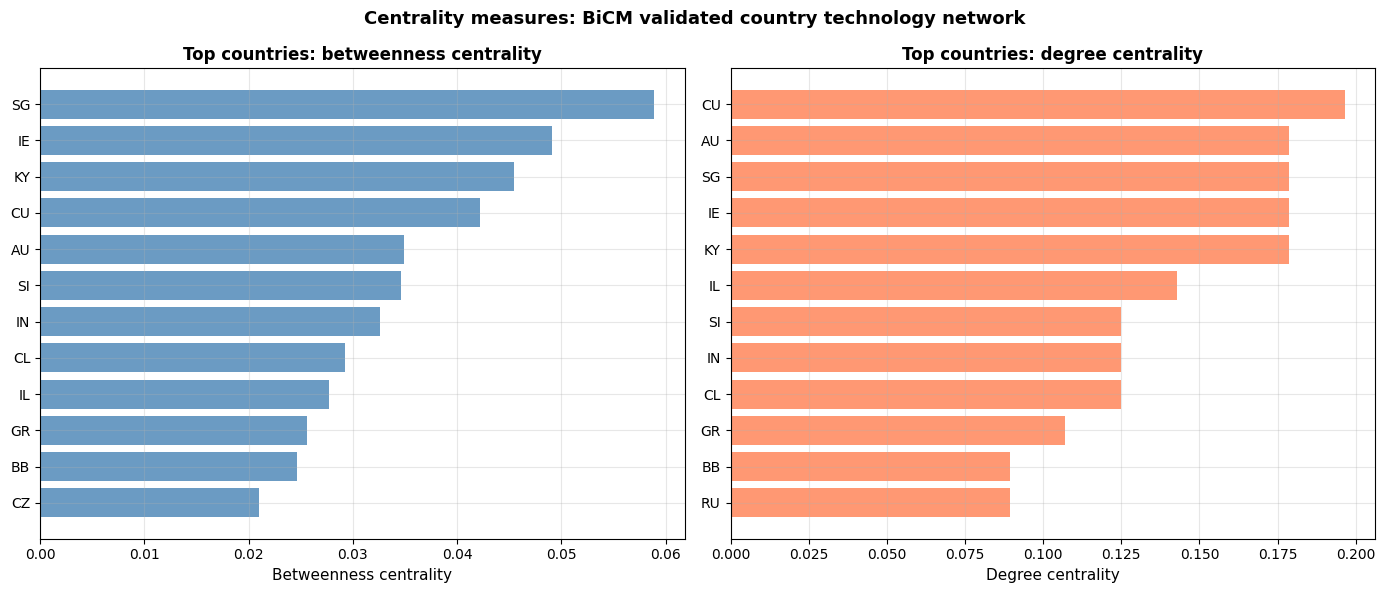

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_bc = df_bc[df_bc['betweenness'] > 0].head(12)
axes[0].barh(range(len(top_bc)), top_bc['betweenness'].values, color='steelblue', alpha=0.8)
axes[0].set_yticks(range(len(top_bc))); axes[0].set_yticklabels(top_bc['country'].values)
axes[0].invert_yaxis()
axes[0].set_xlabel('Betweenness centrality', fontsize=11)
axes[0].set_title('Top countries: betweenness centrality', fontsize=12, fontweight='bold')

top_dc = df_dc[df_dc['degree_centrality'] > 0].head(12)
axes[1].barh(range(len(top_dc)), top_dc['degree_centrality'].values, color='coral', alpha=0.8)
axes[1].set_yticks(range(len(top_dc))); axes[1].set_yticklabels(top_dc['country'].values)
axes[1].invert_yaxis()
axes[1].set_xlabel('Degree centrality', fontsize=11)
axes[1].set_title('Top countries: degree centrality', fontsize=12, fontweight='bold')

plt.suptitle('Centrality measures: BiCM validated country technology network',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Main insights**

The two bar charts show which countries are the most important in the validated network.

- The **Degree centrality** plot shows how many direct validated links each country has. **Cuba (CU)** is first, with **11 direct connections**, followed by **Australia, Singapore, Ireland, and Cayman Islands**, each with **10 connections**. These are the countries that share significant technology links with the largest number of other countries.

- The **Betweenness centrality** plot shows how often a country lies on the shortest path between other countries. This means it measures which countries act more like **bridges** in the network. Here, **Singapore (SG)** ranks first, followed by **Ireland (IE)**, **Cayman Islands (KY)**, and **Cuba (CU)**. So even though Cuba has the most direct links, Singapore seems to play a more important role in connecting different parts of the network.

This difference between the two rankings is useful. It shows that having many links is not exactly the same as being a strong bridge between groups. Another important result is that the countries at the top are **not the biggest patent filers**. Instead, they are mostly **smaller and more focused countries**. In the naive network, the most central countries would probably be the largest patenting countries, such as the US, Japan, China, or Germany. But in the BiCM validated network, these countries are isolated. This means that in the validated network, **specific technology focus matters more than size**.

## References

1. **Saracco, F., Di Clemente, R., Gabrielli, A., & Squartini, T. (2017).** Inferring monopartite projections of bipartite networks: an entropy-based approach. *New Journal of Physics*, 19(5), 053022.

2. **Soete, L., and Wyatt, S. (1983).** The use of foreign patenting as an internationally comparable science and technology output indicator. *Scientometrics*, 5(1), 31–54.

3. **OECD (2009).** *OECD Patent Statistics Manual.* OECD Publishing, Paris. https://www.oecd.org/en/publications/2009/02/oecd-patent-statistics-manual_g1gh9fa4.html

4. **World Intellectual Property Organization (WIPO).** International Patent Classification (IPC). https://www.wipo.int/ipc/en/
   *(IPC code descriptions used for the top-20 ubiquity bar chart.)*